In [1]:
import os
import pandas as pd
import numpy as np

In [2]:
from pathlib import Path


DATA_DIR = Path("../data/raw")

# Find all CSV files inside the dataset folder
csv_files = list(DATA_DIR.rglob("*.csv"))

# Display the discovered files
print("Total CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

Total CSV files: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [3]:
# Check the size of each dataset file

for file in csv_files:
    size_mb = file.stat().st_size / (1024 * 1024)
    print(f"{file.name}: {size_mb:.2f} MB")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 91.65 MB
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 97.16 MB
Friday-WorkingHours-Morning.pcap_ISCX.csv: 71.89 MB
Monday-WorkingHours.pcap_ISCX.csv: 256.20 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 103.69 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 87.77 MB
Tuesday-WorkingHours.pcap_ISCX.csv: 166.60 MB
Wednesday-workingHours.pcap_ISCX.csv: 272.41 MB


In [4]:
# Calculate the total size of all dataset files

total_size_mb = sum(file.stat().st_size for file in csv_files) / (1024 * 1024)

print(f"Total dataset size: {total_size_mb:.2f} MB")
print(f"Total dataset size: {total_size_mb / 1024:.2f} GB")

Total dataset size: 1147.37 MB
Total dataset size: 1.12 GB


In [5]:
# Take a quick look at the first dataset file

first_file = csv_files[0]

df_preview = pd.read_csv(first_file, nrows=5)

# Display the first five records
df_preview

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.5-104.16.207.165-54865-443-6,104.16.207.165,443,192.168.10.5,54865,6,7/7/2017 3:30,3,2,0,...,20,0,0,0,0,0,0,0,0,BENIGN
1,192.168.10.5-104.16.28.216-55054-80-6,104.16.28.216,80,192.168.10.5,55054,6,7/7/2017 3:30,109,1,1,...,20,0,0,0,0,0,0,0,0,BENIGN
2,192.168.10.5-104.16.28.216-55055-80-6,104.16.28.216,80,192.168.10.5,55055,6,7/7/2017 3:30,52,1,1,...,20,0,0,0,0,0,0,0,0,BENIGN
3,192.168.10.16-104.17.241.25-46236-443-6,104.17.241.25,443,192.168.10.16,46236,6,7/7/2017 3:30,34,1,1,...,20,0,0,0,0,0,0,0,0,BENIGN
4,192.168.10.5-104.19.196.102-54863-443-6,104.19.196.102,443,192.168.10.5,54863,6,7/7/2017 3:30,3,2,0,...,20,0,0,0,0,0,0,0,0,BENIGN


In [6]:
# Load a few records to understand the dataset structure

first_file = csv_files[0]

df_preview = pd.read_csv(first_file, nrows=5)

# Display the sample records
df_preview

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.5-104.16.207.165-54865-443-6,104.16.207.165,443,192.168.10.5,54865,6,7/7/2017 3:30,3,2,0,...,20,0,0,0,0,0,0,0,0,BENIGN
1,192.168.10.5-104.16.28.216-55054-80-6,104.16.28.216,80,192.168.10.5,55054,6,7/7/2017 3:30,109,1,1,...,20,0,0,0,0,0,0,0,0,BENIGN
2,192.168.10.5-104.16.28.216-55055-80-6,104.16.28.216,80,192.168.10.5,55055,6,7/7/2017 3:30,52,1,1,...,20,0,0,0,0,0,0,0,0,BENIGN
3,192.168.10.16-104.17.241.25-46236-443-6,104.17.241.25,443,192.168.10.16,46236,6,7/7/2017 3:30,34,1,1,...,20,0,0,0,0,0,0,0,0,BENIGN
4,192.168.10.5-104.19.196.102-54863-443-6,104.19.196.102,443,192.168.10.5,54863,6,7/7/2017 3:30,3,2,0,...,20,0,0,0,0,0,0,0,0,BENIGN


In [7]:
# Check the number of columns and their data types

print("Total columns:", len(df_preview.columns))

column_info = pd.DataFrame({
    "Column Name": df_preview.columns,
    "Data Type": df_preview.dtypes.astype(str).values
})

column_info

Total columns: 85


,Column Name,Data Type
0,Flow ID,object
1,Source IP,object
2,Source Port,int64
3,Destination IP,object
4,Destination Port,int64
...,...,...
80,Idle Mean,int64
81,Idle Std,int64
82,Idle Max,int64
83,Idle Min,int64


In [60]:
# Display all column names in the dataset

for number, column in enumerate(df_preview.columns, start=1):
    print(number, column)

1 Flow ID
2  Source IP
3  Source Port
4  Destination IP
5  Destination Port
6  Protocol
7  Timestamp
8  Flow Duration
9  Total Fwd Packets
10  Total Backward Packets
11 Total Length of Fwd Packets
12  Total Length of Bwd Packets
13  Fwd Packet Length Max
14  Fwd Packet Length Min
15  Fwd Packet Length Mean
16  Fwd Packet Length Std
17 Bwd Packet Length Max
18  Bwd Packet Length Min
19  Bwd Packet Length Mean
20  Bwd Packet Length Std
21 Flow Bytes/s
22  Flow Packets/s
23  Flow IAT Mean
24  Flow IAT Std
25  Flow IAT Max
26  Flow IAT Min
27 Fwd IAT Total
28  Fwd IAT Mean
29  Fwd IAT Std
30  Fwd IAT Max
31  Fwd IAT Min
32 Bwd IAT Total
33  Bwd IAT Mean
34  Bwd IAT Std
35  Bwd IAT Max
36  Bwd IAT Min
37 Fwd PSH Flags
38  Bwd PSH Flags
39  Fwd URG Flags
40  Bwd URG Flags
41  Fwd Header Length
42  Bwd Header Length
43 Fwd Packets/s
44  Bwd Packets/s
45  Min Packet Length
46  Max Packet Length
47  Packet Length Mean
48  Packet Length Std
49  Packet Length Variance
50 FIN Flag Count
51  SYN Fl

In [61]:
# Display the first group of column names

for number, column in enumerate(df_preview.columns[:30], start=1):
    print(number, column)

1 Flow ID
2  Source IP
3  Source Port
4  Destination IP
5  Destination Port
6  Protocol
7  Timestamp
8  Flow Duration
9  Total Fwd Packets
10  Total Backward Packets
11 Total Length of Fwd Packets
12  Total Length of Bwd Packets
13  Fwd Packet Length Max
14  Fwd Packet Length Min
15  Fwd Packet Length Mean
16  Fwd Packet Length Std
17 Bwd Packet Length Max
18  Bwd Packet Length Min
19  Bwd Packet Length Mean
20  Bwd Packet Length Std
21 Flow Bytes/s
22  Flow Packets/s
23  Flow IAT Mean
24  Flow IAT Std
25  Flow IAT Max
26  Flow IAT Min
27 Fwd IAT Total
28  Fwd IAT Mean
29  Fwd IAT Std
30  Fwd IAT Max


In [62]:
# Display the second group of column names

for number, column in enumerate(df_preview.columns[30:60], start=31):
    print(number, column)

31  Fwd IAT Min
32 Bwd IAT Total
33  Bwd IAT Mean
34  Bwd IAT Std
35  Bwd IAT Max
36  Bwd IAT Min
37 Fwd PSH Flags
38  Bwd PSH Flags
39  Fwd URG Flags
40  Bwd URG Flags
41  Fwd Header Length
42  Bwd Header Length
43 Fwd Packets/s
44  Bwd Packets/s
45  Min Packet Length
46  Max Packet Length
47  Packet Length Mean
48  Packet Length Std
49  Packet Length Variance
50 FIN Flag Count
51  SYN Flag Count
52  RST Flag Count
53  PSH Flag Count
54  ACK Flag Count
55  URG Flag Count
56  CWE Flag Count
57  ECE Flag Count
58  Down/Up Ratio
59  Average Packet Size
60  Avg Fwd Segment Size


In [63]:
# Display the remaining column names

for number, column in enumerate(df_preview.columns[60:], start=61):
    print(number, column)

61  Avg Bwd Segment Size
62  Fwd Header Length.1
63 Fwd Avg Bytes/Bulk
64  Fwd Avg Packets/Bulk
65  Fwd Avg Bulk Rate
66  Bwd Avg Bytes/Bulk
67  Bwd Avg Packets/Bulk
68 Bwd Avg Bulk Rate
69 Subflow Fwd Packets
70  Subflow Fwd Bytes
71  Subflow Bwd Packets
72  Subflow Bwd Bytes
73 Init_Win_bytes_forward
74  Init_Win_bytes_backward
75  act_data_pkt_fwd
76  min_seg_size_forward
77 Active Mean
78  Active Std
79  Active Max
80  Active Min
81 Idle Mean
82  Idle Std
83  Idle Max
84  Idle Min
85  Label


In [12]:
# Check the number of columns in all eight CSV files

for file in csv_files:
    df_check = pd.read_csv(file, nrows=0)
    print(file.name, ":", len(df_check.columns), "columns")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv : 85 columns
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv : 85 columns
Friday-WorkingHours-Morning.pcap_ISCX.csv : 85 columns
Monday-WorkingHours.pcap_ISCX.csv : 85 columns
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv : 85 columns
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv : 85 columns
Tuesday-WorkingHours.pcap_ISCX.csv : 85 columns
Wednesday-workingHours.pcap_ISCX.csv : 85 columns


In [64]:
# Check whether all eight files have identical column names

reference_columns = pd.read_csv(csv_files[0], nrows=0).columns.tolist()

for file in csv_files[1:]:
    current_columns = pd.read_csv(file, nrows=0).columns.tolist()

    if current_columns == reference_columns:
        print(file.name, "-> Matching columns")
    else:
        print(file.name, "-> Column mismatch")

Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv -> Matching columns
Friday-WorkingHours-Morning.pcap_ISCX.csv -> Matching columns
Monday-WorkingHours.pcap_ISCX.csv -> Matching columns
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv -> Matching columns
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv -> Matching columns
Tuesday-WorkingHours.pcap_ISCX.csv -> Matching columns
Wednesday-workingHours.pcap_ISCX.csv -> Matching columns


In [65]:
# Store the verified column names

all_columns = reference_columns

# Display all column names

for number, column in enumerate(all_columns, start=1):
    print(f"{number}. {column}")

1. Flow ID
2.  Source IP
3.  Source Port
4.  Destination IP
5.  Destination Port
6.  Protocol
7.  Timestamp
8.  Flow Duration
9.  Total Fwd Packets
10.  Total Backward Packets
11. Total Length of Fwd Packets
12.  Total Length of Bwd Packets
13.  Fwd Packet Length Max
14.  Fwd Packet Length Min
15.  Fwd Packet Length Mean
16.  Fwd Packet Length Std
17. Bwd Packet Length Max
18.  Bwd Packet Length Min
19.  Bwd Packet Length Mean
20.  Bwd Packet Length Std
21. Flow Bytes/s
22.  Flow Packets/s
23.  Flow IAT Mean
24.  Flow IAT Std
25.  Flow IAT Max
26.  Flow IAT Min
27. Fwd IAT Total
28.  Fwd IAT Mean
29.  Fwd IAT Std
30.  Fwd IAT Max
31.  Fwd IAT Min
32. Bwd IAT Total
33.  Bwd IAT Mean
34.  Bwd IAT Std
35.  Bwd IAT Max
36.  Bwd IAT Min
37. Fwd PSH Flags
38.  Bwd PSH Flags
39.  Fwd URG Flags
40.  Bwd URG Flags
41.  Fwd Header Length
42.  Bwd Header Length
43. Fwd Packets/s
44.  Bwd Packets/s
45.  Min Packet Length
46.  Max Packet Length
47.  Packet Length Mean
48.  Packet Length Std
49.  Pa

In [66]:
# Check for missing values in the first dataset file

df_check = pd.read_csv(first_file)

missing_values = df_check.isnull().sum()

print("Total missing values:", missing_values.sum())

missing_values[missing_values > 0]

Total missing values: 4


Flow Bytes/s    4
dtype: int64

In [16]:
# Calculate the percentage of missing values in each column

missing_percentage = (df_check.isnull().sum() / len(df_check)) * 100

missing_percentage[missing_percentage > 0]

Flow Bytes/s    0.001772
dtype: float64

In [67]:
# Check how many duplicate records are present

duplicate_count = df_check.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 2


In [68]:
# Check for infinite values in numerical columns

numeric_df = df_check.select_dtypes(include="number")

infinite_count = np.isinf(numeric_df).sum().sum()

print("Total infinite values:", infinite_count)

Total infinite values: 64


In [69]:
# Find columns containing infinite values

infinite_by_column = np.isinf(numeric_df).sum()

infinite_by_column[infinite_by_column > 0]

Flow Bytes/s       30
 Flow Packets/s    34
dtype: int64

In [70]:
# Find columns containing infinite values

infinite_by_column = np.isinf(numeric_df).sum()

infinite_by_column[infinite_by_column > 0]

Flow Bytes/s       30
 Flow Packets/s    34
dtype: int64

In [21]:
# Check the exact Flow Duration column name

for column in df_check.columns:
    if "Flow Duration" in column:
        print(repr(column))

' Flow Duration'


In [71]:
# Remove unwanted spaces from column names

df_check.columns = df_check.columns.str.strip()

print("Updated column name:", repr(df_check.columns[7]))

Updated column name: 'Flow Duration'


In [72]:
# Check how many network flows have zero duration

zero_duration_count = (df_check["Flow Duration"] == 0).sum()

print("Zero-duration records:", zero_duration_count)

Zero-duration records: 34


In [74]:
# Compare zero-duration records with infinite packet rates

zero_duration_mask = df_check["Flow Duration"] == 0

infinite_packet_rate = np.isinf(df_check["Flow Packets/s"])

print(
    "Zero duration AND infinite packet rate:",
    (zero_duration_mask & infinite_packet_rate).sum()
)


Zero duration AND infinite packet rate: 34


In [25]:
# Compare zero-duration records with infinite byte rates

infinite_byte_rate = np.isinf(df_check["Flow Bytes/s"])

print(
    "Zero duration AND infinite byte rate:",
    (zero_duration_mask & infinite_byte_rate).sum()
)

Zero duration AND infinite byte rate: 30


In [75]:
# View records with zero flow duration

df_check.loc[
    zero_duration_mask,
    ["Flow Duration", "Flow Bytes/s", "Flow Packets/s", "Label"]
].head(10)

,Flow Duration,Flow Bytes/s,Flow Packets/s,Label
65,0,inf,inf,BENIGN
1767,0,inf,inf,BENIGN
1890,0,inf,inf,BENIGN
3375,0,inf,inf,BENIGN
6796,0,NaN,inf,BENIGN
8057,0,inf,inf,BENIGN
8405,0,inf,inf,BENIGN
13313,0,inf,inf,BENIGN
13716,0,inf,inf,BENIGN
14739,0,NaN,inf,BENIGN


In [76]:
# Check the labels of all zero-duration records

zero_duration_labels = df_check.loc[
    zero_duration_mask, "Label"
].value_counts(dropna=False)

zero_duration_labels

Label
BENIGN    32
DDoS       2
Name: count, dtype: int64

In [77]:
# Count records belonging to each traffic category

label_distribution = df_check["Label"].value_counts(dropna=False)

print(label_distribution)

Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64


In [79]:
# Check the timestamp column's data type

print("Timestamp data type:", df_check["Timestamp"].dtype)

# Display a few timestamp values
df_check["Timestamp"].head()

Timestamp data type: object


0    7/7/2017 3:30
1    7/7/2017 3:30
2    7/7/2017 3:30
3    7/7/2017 3:30
4    7/7/2017 3:30
Name: Timestamp, dtype: object

In [80]:
# Check for missing timestamps

print(
    "Missing timestamps:",
    df_check["Timestamp"].isnull().sum()
)

Missing timestamps: 0


In [81]:
# Convert timestamp values into datetime format

df_check["Timestamp"] = pd.to_datetime(
    df_check["Timestamp"],
    format="%m/%d/%Y %H:%M",
    errors="coerce"
)

print("Updated data type:", df_check["Timestamp"].dtype)
print("Missing timestamps after conversion:", df_check["Timestamp"].isnull().sum())

Updated data type: datetime64[ns]
Missing timestamps after conversion: 0


In [82]:
# Find the earliest and latest timestamps

print("First timestamp:", df_check["Timestamp"].min())
print("Last timestamp:", df_check["Timestamp"].max())


First timestamp: 2017-07-07 03:30:00
Last timestamp: 2017-07-07 05:02:00


In [83]:
# Extract the weekday from each timestamp

df_check["Weekday"] = df_check["Timestamp"].dt.day_name()

df_check["Weekday"].value_counts()

Weekday
Friday    225745
Name: count, dtype: int64

In [84]:
# Extract the hour from each timestamp

df_check["Hour"] = df_check["Timestamp"].dt.hour

df_check["Hour"].value_counts().sort_index()

Hour
3     52500
4    171693
5      1552
Name: count, dtype: int64

In [85]:
# Extract the date from each timestamp

df_check["Date"] = df_check["Timestamp"].dt.date

df_check["Date"].value_counts()

Date
2017-07-07    225745
Name: count, dtype: int64

In [86]:
# Check the distribution of network protocols

df_check["Protocol"].value_counts(dropna=False)

Protocol
6     192820
17     32871
0         54
Name: count, dtype: int64

In [37]:
# Inspect records using protocol number 0

df_check.loc[
    df_check["Protocol"] == 0,
    ["Protocol", "Source IP", "Destination IP", "Source Port",
     "Destination Port", "Label"]
].head(10)


,Protocol,Source IP,Destination IP,Source Port,Destination Port,Label
3630,0,8.6.0.1,8.0.6.4,0,0,BENIGN
5417,0,8.6.0.1,8.0.6.4,0,0,BENIGN
6859,0,8.6.0.1,8.0.6.4,0,0,BENIGN
9563,0,8.6.0.1,8.0.6.4,0,0,BENIGN
11144,0,192.168.10.50,192.168.10.3,0,0,BENIGN
11543,0,8.6.0.1,8.0.6.4,0,0,BENIGN
13349,0,8.6.0.1,8.0.6.4,0,0,BENIGN
13653,0,8.6.0.1,8.0.6.4,0,0,BENIGN
13720,0,192.168.10.16,192.168.10.3,0,0,BENIGN
14809,0,8.6.0.1,8.0.6.4,0,0,BENIGN


In [87]:
# Check the traffic categories for protocol 0

protocol_zero_labels = df_check.loc[
    df_check["Protocol"] == 0,
    "Label"
].value_counts(dropna=False)

protocol_zero_labels

Label
BENIGN    54
Name: count, dtype: int64

In [88]:
# Identify which CSV file causes the encoding error

for file in csv_files:
    try:
        for chunk in pd.read_csv(file, chunksize=100000):
            pass

        print(file.name, "-> Read successfully")

    except UnicodeDecodeError as error:
        print(file.name, "-> Encoding error")
        print("Error details:", error)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv -> Read successfully
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv -> Read successfully
Friday-WorkingHours-Morning.pcap_ISCX.csv -> Read successfully
Monday-WorkingHours.pcap_ISCX.csv -> Read successfully
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv -> Read successfully
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv -> Encoding error
Error details: 'utf-8' codec can't decode byte 0x96 in position 22398: invalid start byte
Tuesday-WorkingHours.pcap_ISCX.csv -> Read successfully
Wednesday-workingHours.pcap_ISCX.csv -> Read successfully


In [89]:
# Test whether Windows-1252 can read the problematic CSV

problem_file = next(
    file for file in csv_files
    if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
)

try:
    test_rows = 0

    for chunk in pd.read_csv(
        problem_file,
        encoding="cp1252",
        chunksize=100000
    ):
        test_rows += len(chunk)

    print("Encoding test successful!")
    print("Total records read:", test_rows)

except Exception as error:
    print("Encoding test failed:", error)

C:\Users\luvmi\AppData\Local\Temp\ipykernel_39300\2732708037.py:11: DtypeWarning: Columns (0,1,3,6,84) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(


Encoding test successful!
Total records read: 458968


In [90]:
# Summarise records and traffic labels across all eight CSV files

file_summaries = []

for file in csv_files:

    # Select the correct encoding for each file
    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    total_rows = 0
    label_counts = {}

    # Read only the Label column in manageable chunks
    for chunk in pd.read_csv(
        file,
        usecols=lambda column: column.strip() == "Label",
        encoding=encoding,
        chunksize=100000
    ):

        chunk.columns = chunk.columns.str.strip()
        total_rows += len(chunk)

        counts = chunk["Label"].value_counts(dropna=False)

        for label, count in counts.items():
            label_counts[label] = label_counts.get(label, 0) + count

    file_summaries.append({
        "File": file.name,
        "Total Records": total_rows,
        "Labels": label_counts
    })

file_summary_df = pd.DataFrame(file_summaries)

file_summary_df

C:\Users\luvmi\AppData\Local\Temp\ipykernel_39300\3152030630.py:18: DtypeWarning: Columns (84) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(


,File,Total Records,Labels
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,"{'DDoS': 128027, 'BENIGN': 97718}"
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,"{'BENIGN': 127537, 'PortScan': 158930}"
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,"{'BENIGN': 189067, 'Bot': 1966}"
3,Monday-WorkingHours.pcap_ISCX.csv,529918,{'BENIGN': 529918}
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,"{'BENIGN': 288566, 'Infiltration': 36}"
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,458968,"{'BENIGN': 168186, 'Web Attack – Brute Force':..."
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,"{'BENIGN': 432074, 'FTP-Patator': 7938, 'SSH-P..."
7,Wednesday-workingHours.pcap_ISCX.csv,692703,"{'BENIGN': 440031, 'DoS Hulk': 231073, 'DoS sl..."


In [91]:
# Convert the label dictionaries into a readable table

label_summary = []

for summary in file_summaries:
    for label, count in summary["Labels"].items():
        label_summary.append({
            "File": summary["File"],
            "Label": label,
            "Count": count
        })

label_summary_df = pd.DataFrame(label_summary)

label_summary_df

,File,Label,Count
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,DDoS,128027
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,BENIGN,97718
2,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,BENIGN,127537
3,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,PortScan,158930
4,Friday-WorkingHours-Morning.pcap_ISCX.csv,BENIGN,189067
5,Friday-WorkingHours-Morning.pcap_ISCX.csv,Bot,1966
6,Monday-WorkingHours.pcap_ISCX.csv,BENIGN,529918
7,Thursday-WorkingHours-Afternoon-Infilteration....,BENIGN,288566
8,Thursday-WorkingHours-Afternoon-Infilteration....,Infiltration,36
9,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,BENIGN,168186


In [92]:
# Inspect missing labels in the Thursday WebAttacks file

missing_label_rows = 0
total_label_rows = 0

for chunk in pd.read_csv(
    problem_file,
    encoding="cp1252",
    usecols=lambda column: column.strip() == "Label",
    chunksize=100000
):
    chunk.columns = chunk.columns.str.strip()

    total_label_rows += len(chunk)
    missing_label_rows += chunk["Label"].isna().sum()

print("Total records:", total_label_rows)
print("Missing labels:", missing_label_rows)
print(
    "Missing label percentage:",
    round(missing_label_rows / total_label_rows * 100, 2),
    "%"
)

C:\Users\luvmi\AppData\Local\Temp\ipykernel_39300\3139865962.py:6: DtypeWarning: Columns (84) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(


Total records: 458968
Missing labels: 288602
Missing label percentage: 62.88 %


In [93]:
# Inspect actual records with missing labels

for chunk in pd.read_csv(
    problem_file,
    encoding="cp1252",
    chunksize=100000,
    low_memory=False
):
    chunk.columns = chunk.columns.str.strip()

    missing_rows = chunk[chunk["Label"].isna()]

    if not missing_rows.empty:

        print("First records with missing labels:")

        display(
            missing_rows[
                ["Flow ID", "Source IP", "Destination IP",
                 "Timestamp", "Flow Duration", "Label"]
            ].head(5)
        )

        print("\nMissing values across these records:")

        print(missing_rows.head(5).isna().sum())

        break

First records with missing labels:


,Flow ID,Source IP,Destination IP,Timestamp,Flow Duration,Label
170366,NaN,NaN,NaN,NaN,NaN,NaN
170367,NaN,NaN,NaN,NaN,NaN,NaN
170368,NaN,NaN,NaN,NaN,NaN,NaN
170369,NaN,NaN,NaN,NaN,NaN,NaN
170370,NaN,NaN,NaN,NaN,NaN,NaN



Missing values across these records:
Flow ID             5
Source IP           5
Source Port         5
Destination IP      5
Destination Port    5
                   ..
Idle Mean           5
Idle Std            5
Idle Max            5
Idle Min            5
Label               5
Length: 85, dtype: int64


In [94]:
# Count completely empty rows in the Thursday WebAttacks file

blank_rows = 0
total_rows = 0

for chunk in pd.read_csv(
    problem_file,
    encoding="cp1252",
    chunksize=100000,
    low_memory=False
):
    chunk.columns = chunk.columns.str.strip()

    total_rows += len(chunk)
    blank_rows += chunk.isna().all(axis=1).sum()

print("Total records:", total_rows)
print("Completely blank rows:", blank_rows)

Total records: 458968
Completely blank rows: 288602


In [95]:
# Check where completely blank rows occur

first_blank_index = None
last_nonblank_after_blank = None

for chunk in pd.read_csv(
    problem_file,
    encoding="cp1252",
    chunksize=100000,
    low_memory=False
):
    chunk.columns = chunk.columns.str.strip()

    blank_mask = chunk.isna().all(axis=1)

    if blank_mask.any() and first_blank_index is None:
        first_blank_index = blank_mask[blank_mask].index[0]

    if first_blank_index is not None:
        nonblank_after = chunk[
            (~blank_mask) & (chunk.index > first_blank_index)
        ]

        if not nonblank_after.empty:
            last_nonblank_after_blank = nonblank_after.index[-1]

print("First blank row index:", first_blank_index)
print("Last non-blank row after first blank:", last_nonblank_after_blank)

First blank row index: 170366
Last non-blank row after first blank: None


In [96]:
# Check completely blank rows across all eight CSV files

blank_row_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    total_rows = 0
    blank_rows = 0

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()

        total_rows += len(chunk)
        blank_rows += chunk.isna().all(axis=1).sum()

    blank_row_summary.append({
        "File": file.name,
        "Total Rows": total_rows,
        "Completely Blank Rows": blank_rows,
        "Valid Rows": total_rows - blank_rows
    })

blank_row_df = pd.DataFrame(blank_row_summary)

blank_row_df

,File,Total Rows,Completely Blank Rows,Valid Rows
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,0,225745
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,0,286467
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,0,191033
3,Monday-WorkingHours.pcap_ISCX.csv,529918,0,529918
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,0,288602
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,458968,288602,170366
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,0,445909
7,Wednesday-workingHours.pcap_ISCX.csv,692703,0,692703


In [97]:
# Check missing values in individual columns across all CSV files

missing_value_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    missing_counts = {}
    valid_rows = 0

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()

        # Exclude completely blank rows from this assessment
        chunk = chunk.dropna(how="all")

        valid_rows += len(chunk)

        counts = chunk.isna().sum()

        for column, count in counts.items():
            missing_counts[column] = (
                missing_counts.get(column, 0) + count
            )

    for column, count in missing_counts.items():

        if count > 0:
            missing_value_summary.append({
                "File": file.name,
                "Column": column,
                "Missing Values": count,
                "Missing Percentage": round(
                    count / valid_rows * 100, 4
                )
            })

missing_value_df = pd.DataFrame(missing_value_summary)

missing_value_df

,File,Column,Missing Values,Missing Percentage
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Bytes/s,4,0.0018
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow Bytes/s,15,0.0052
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Bytes/s,28,0.0147
3,Monday-WorkingHours.pcap_ISCX.csv,Flow Bytes/s,64,0.0121
4,Thursday-WorkingHours-Afternoon-Infilteration....,Flow Bytes/s,18,0.0062
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,Flow Bytes/s,20,0.0117
6,Tuesday-WorkingHours.pcap_ISCX.csv,Flow Bytes/s,201,0.0451
7,Wednesday-workingHours.pcap_ISCX.csv,Flow Bytes/s,1008,0.1455


In [98]:
# Find records with missing Flow Bytes/s in Wednesday's dataset

wednesday_file = next(
    file for file in csv_files
    if "Wednesday-workingHours" in file.name
)

for chunk in pd.read_csv(
    wednesday_file,
    chunksize=100000,
    low_memory=False
):
    chunk.columns = chunk.columns.str.strip()

    missing_rows = chunk[chunk["Flow Bytes/s"].isna()]

    if not missing_rows.empty:
        display(
            missing_rows[
                ["Flow Duration", "Total Length of Fwd Packets",
                 "Total Length of Bwd Packets", "Flow Bytes/s",
                 "Flow Packets/s", "Label"]
            ].head(10)
        )
        break

,Flow Duration,Total Length of Fwd Packets,Total Length of Bwd Packets,Flow Bytes/s,Flow Packets/s,Label
5106,0,0,0.0,NaN,inf,BENIGN
5833,0,0,0.0,NaN,inf,BENIGN
8381,0,0,0.0,NaN,inf,BENIGN
8552,0,0,0.0,NaN,inf,BENIGN
14762,0,0,0.0,NaN,inf,BENIGN
33958,0,0,0.0,NaN,inf,BENIGN
33959,0,0,0.0,NaN,inf,BENIGN
41911,0,0,0.0,NaN,inf,BENIGN
44498,0,0,0.0,NaN,inf,BENIGN
58667,0,0,0.0,NaN,inf,BENIGN


In [99]:
# Investigate all missing Flow Bytes/s records in Wednesday's file

missing_flow_summary = {
    "Total missing Flow Bytes/s": 0,
    "Zero Flow Duration": 0,
    "Infinite Flow Packets/s": 0,
    "Zero Forward Packet Length": 0,
    "Zero Backward Packet Length": 0
}

for chunk in pd.read_csv(
    wednesday_file,
    chunksize=100000,
    low_memory=False
):
    chunk.columns = chunk.columns.str.strip()

    missing_rows = chunk[chunk["Flow Bytes/s"].isna()]

    missing_flow_summary["Total missing Flow Bytes/s"] += len(missing_rows)
    missing_flow_summary["Zero Flow Duration"] += (missing_rows["Flow Duration"] == 0).sum()
    missing_flow_summary["Infinite Flow Packets/s"] += np.isinf(missing_rows["Flow Packets/s"]).sum()
    missing_flow_summary["Zero Forward Packet Length"] += (missing_rows["Total Length of Fwd Packets"] == 0).sum()
    missing_flow_summary["Zero Backward Packet Length"] += (missing_rows["Total Length of Bwd Packets"] == 0).sum()

pd.Series(missing_flow_summary)

KeyboardInterrupt: 

In [ ]:
# Check whether missing Flow Bytes/s is associated with zero duration

flow_missing_checks = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    total_missing = 0
    zero_duration = 0
    infinite_packet_rate = 0

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        missing_rows = chunk[chunk["Flow Bytes/s"].isna()]

        total_missing += len(missing_rows)
        zero_duration += (
            missing_rows["Flow Duration"] == 0
        ).sum()
        infinite_packet_rate += np.isinf(
            missing_rows["Flow Packets/s"]
        ).sum()

    flow_missing_checks.append({
        "File": file.name,
        "Missing Flow Bytes/s": total_missing,
        "Zero Duration": zero_duration,
        "Infinite Packet Rate": infinite_packet_rate
    })

flow_missing_df = pd.DataFrame(flow_missing_checks)

flow_missing_df

,File,Missing Flow Bytes/s,Zero Duration,Infinite Packet Rate
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,4,4,4
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,15,15,15
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,28,28,28
3,Monday-WorkingHours.pcap_ISCX.csv,64,64,64
4,Thursday-WorkingHours-Afternoon-Infilteration....,18,18,18
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,20,20,20
6,Tuesday-WorkingHours.pcap_ISCX.csv,201,201,201
7,Wednesday-workingHours.pcap_ISCX.csv,1008,1008,1008


In [ ]:
# Check infinite values across all eight CSV files

infinity_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    infinity_counts = {}
    total_rows = 0

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()

        # Exclude completely blank rows
        chunk = chunk.dropna(how="all")

        total_rows += len(chunk)

        # Select numerical columns
        numeric_chunk = chunk.select_dtypes(include="number")

        # Count positive and negative infinity values
        counts = np.isinf(numeric_chunk).sum()

        for column, count in counts.items():
            infinity_counts[column] = (
                infinity_counts.get(column, 0) + count
            )

    for column, count in infinity_counts.items():

        if count > 0:
            infinity_summary.append({
                "File": file.name,
                "Column": column,
                "Infinite Values": count
            })

infinity_df = pd.DataFrame(infinity_summary)

infinity_df

,File,Column,Infinite Values
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Bytes/s,30
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Packets/s,34
2,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow Bytes/s,356
3,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow Packets/s,371
4,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Bytes/s,94
5,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Packets/s,122
6,Monday-WorkingHours.pcap_ISCX.csv,Flow Bytes/s,373
7,Monday-WorkingHours.pcap_ISCX.csv,Flow Packets/s,437
8,Thursday-WorkingHours-Afternoon-Infilteration....,Flow Bytes/s,189
9,Thursday-WorkingHours-Afternoon-Infilteration....,Flow Packets/s,207


In [ ]:
# Check whether infinite flow rates occur in zero-duration records

infinity_duration_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    total_inf_bytes = 0
    inf_bytes_zero_duration = 0

    total_inf_packets = 0
    inf_packets_zero_duration = 0

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        zero_duration = chunk["Flow Duration"] == 0

        inf_bytes = np.isinf(chunk["Flow Bytes/s"])
        inf_packets = np.isinf(chunk["Flow Packets/s"])

        total_inf_bytes += inf_bytes.sum()
        inf_bytes_zero_duration += (inf_bytes & zero_duration).sum()

        total_inf_packets += inf_packets.sum()
        inf_packets_zero_duration += (inf_packets & zero_duration).sum()

    infinity_duration_summary.append({
        "File": file.name,
        "Infinite Bytes/s": total_inf_bytes,
        "Bytes/s with Zero Duration": inf_bytes_zero_duration,
        "Infinite Packets/s": total_inf_packets,
        "Packets/s with Zero Duration": inf_packets_zero_duration
    })

infinity_duration_df = pd.DataFrame(infinity_duration_summary)

infinity_duration_df

,File,Infinite Bytes/s,Bytes/s with Zero Duration,Infinite Packets/s,Packets/s with Zero Duration
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,30,30,34,34
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,356,356,371,371
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,94,94,122,122
3,Monday-WorkingHours.pcap_ISCX.csv,373,373,437,437
4,Thursday-WorkingHours-Afternoon-Infilteration....,189,189,207,207
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,115,115,135,135
6,Tuesday-WorkingHours.pcap_ISCX.csv,63,63,264,264
7,Wednesday-workingHours.pcap_ISCX.csv,289,289,1297,1297


In [ ]:
# Count zero-duration records across all eight CSV files

zero_duration_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    total_valid_rows = 0
    zero_duration_count = 0

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        total_valid_rows += len(chunk)

        zero_duration_count += (
            chunk["Flow Duration"] == 0
        ).sum()

    zero_duration_summary.append({
        "File": file.name,
        "Valid Records": total_valid_rows,
        "Zero Duration Records": zero_duration_count
    })

zero_duration_df = pd.DataFrame(zero_duration_summary)

zero_duration_df

,File,Valid Records,Zero Duration Records
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,34
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,371
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,122
3,Monday-WorkingHours.pcap_ISCX.csv,529918,437
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,207
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,135
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,264
7,Wednesday-workingHours.pcap_ISCX.csv,692703,1297


In [ ]:
# Display the complete zero-duration summary

display(zero_duration_df)

print(
    "Total valid records:",
    zero_duration_df["Valid Records"].sum()
)

print(
    "Total zero-duration records:",
    zero_duration_df["Zero Duration Records"].sum()
)

,File,Valid Records,Zero Duration Records
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,34
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,371
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,122
3,Monday-WorkingHours.pcap_ISCX.csv,529918,437
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,207
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,135
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,264
7,Wednesday-workingHours.pcap_ISCX.csv,692703,1297


Total valid records: 2830743
Total zero-duration records: 2867


In [100]:
# Check duplicate records within each CSV file

duplicate_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    seen_hashes = set()
    duplicate_count = 0

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()

        # Exclude completely blank rows
        chunk = chunk.dropna(how="all")

        # Generate a hash for each complete record
        row_hashes = pd.util.hash_pandas_object(
            chunk,
            index=False
        )

        # Identify records already encountered
        for row_hash in row_hashes:
            if row_hash in seen_hashes:
                duplicate_count += 1
            else:
                seen_hashes.add(row_hash)

    duplicate_summary.append({
        "File": file.name,
        "Duplicate Records": duplicate_count
    })

duplicate_df = pd.DataFrame(duplicate_summary)

duplicate_df

,File,Duplicate Records
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,2
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,1
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,2
3,Monday-WorkingHours.pcap_ISCX.csv,34
4,Thursday-WorkingHours-Afternoon-Infilteration....,142
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,1
6,Tuesday-WorkingHours.pcap_ISCX.csv,4
7,Wednesday-workingHours.pcap_ISCX.csv,17


In [101]:
# Check duplicate records shared between different CSV files

seen_hashes = set()
cross_file_duplicates = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    file_hashes = set()

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        row_hashes = pd.util.hash_pandas_object(
            chunk,
            index=False
        )

        file_hashes.update(row_hashes.tolist())

    # Find records already encountered in earlier files
    shared_hashes = file_hashes.intersection(seen_hashes)

    cross_file_duplicates.append({
        "File": file.name,
        "Cross-file Duplicate Records": len(shared_hashes)
    })

    seen_hashes.update(file_hashes)

cross_file_duplicate_df = pd.DataFrame(cross_file_duplicates)

cross_file_duplicate_df

,File,Cross-file Duplicate Records
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,0
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,0
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,0
3,Monday-WorkingHours.pcap_ISCX.csv,0
4,Thursday-WorkingHours-Afternoon-Infilteration....,0
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,0
6,Tuesday-WorkingHours.pcap_ISCX.csv,0
7,Wednesday-workingHours.pcap_ISCX.csv,0


In [102]:
# Calculate total records for each traffic label

overall_label_summary = (
    label_summary_df
    .dropna(subset=["Label"])
    .groupby("Label", as_index=False)["Count"]
    .sum()
    .sort_values("Count", ascending=False)
    .reset_index(drop=True)
)

overall_label_summary

,Label,Count
0,BENIGN,2273097
1,DoS Hulk,231073
2,PortScan,158930
3,DDoS,128027
4,DoS GoldenEye,10293
5,FTP-Patator,7938
6,SSH-Patator,5897
7,DoS slowloris,5796
8,DoS Slowhttptest,5499
9,Bot,1966


In [103]:
# Calculate the percentage distribution of traffic labels

overall_label_summary["Percentage"] = (
    overall_label_summary["Count"]
    / overall_label_summary["Count"].sum()
    * 100
).round(2)

overall_label_summary

,Label,Count,Percentage
0,BENIGN,2273097,80.30
1,DoS Hulk,231073,8.16
2,PortScan,158930,5.61
3,DDoS,128027,4.52
4,DoS GoldenEye,10293,0.36
5,FTP-Patator,7938,0.28
6,SSH-Patator,5897,0.21
7,DoS slowloris,5796,0.20
8,DoS Slowhttptest,5499,0.19
9,Bot,1966,0.07


In [104]:
# Inspect the exact formatting of traffic labels

for label in sorted(
    label_summary_df["Label"].dropna().unique()
):
    print(repr(label))

'BENIGN'
'Bot'
'DDoS'
'DoS GoldenEye'
'DoS Hulk'
'DoS Slowhttptest'
'DoS slowloris'
'FTP-Patator'
'Heartbleed'
'Infiltration'
'PortScan'
'SSH-Patator'
'Web Attack – Brute Force'
'Web Attack – Sql Injection'
'Web Attack – XSS'


In [105]:
# Inspect column data types across all eight CSV files

dtype_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    observed_dtypes = {}

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()

        for column, dtype in chunk.dtypes.items():
            observed_dtypes.setdefault(column, set()).add(str(dtype))

    for column, dtypes in observed_dtypes.items():
        dtype_summary.append({
            "File": file.name,
            "Column": column,
            "Data Types Found": ", ".join(sorted(dtypes))
        })

dtype_df = pd.DataFrame(dtype_summary)

dtype_df

,File,Column,Data Types Found
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow ID,object
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Source IP,object
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Source Port,int64
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Destination IP,object
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Destination Port,int64
...,...,...,...
675,Wednesday-workingHours.pcap_ISCX.csv,Idle Mean,float64
676,Wednesday-workingHours.pcap_ISCX.csv,Idle Std,float64
677,Wednesday-workingHours.pcap_ISCX.csv,Idle Max,float64
678,Wednesday-workingHours.pcap_ISCX.csv,Idle Min,float64


In [106]:
# Find columns with different data types across files

dtype_inconsistencies = (
    dtype_df.groupby("Column")["Data Types Found"]
    .nunique()
)

inconsistent_columns = dtype_inconsistencies[
    dtype_inconsistencies > 1
]

print("Number of inconsistent columns:", len(inconsistent_columns))

inconsistent_columns

Number of inconsistent columns: 61


Column
ACK Flag Count                 2
Active Max                     2
Active Min                     2
Bwd Avg Bulk Rate              2
Bwd Avg Bytes/Bulk             2
                              ..
Total Length of Bwd Packets    3
Total Length of Fwd Packets    3
URG Flag Count                 2
act_data_pkt_fwd               2
min_seg_size_forward           2
Name: Data Types Found, Length: 61, dtype: int64

In [107]:
# Expand the detected data types for detailed investigation

dtype_details = []

for _, row in dtype_df.iterrows():

    types = row["Data Types Found"].split(", ")

    for data_type in types:
        dtype_details.append({
            "Column": row["Column"],
            "File": row["File"],
            "Data Type": data_type
        })

dtype_details_df = pd.DataFrame(dtype_details)

# Show the different data types found in each column

dtype_comparison = (
    dtype_details_df.groupby("Column")["Data Type"]
    .agg(lambda values: sorted(set(values)))
    .reset_index(name="Observed Data Types")
)

dtype_comparison["Number of Types"] = (
    dtype_comparison["Observed Data Types"].apply(len)
)

dtype_comparison = dtype_comparison[
    dtype_comparison["Number of Types"] > 1
]

dtype_comparison

,Column,Observed Data Types,Number of Types
0,ACK Flag Count,"[float64, int64]",2
1,Active Max,"[float64, int64]",2
3,Active Min,"[float64, int64]",2
8,Bwd Avg Bulk Rate,"[float64, int64]",2
9,Bwd Avg Bytes/Bulk,"[float64, int64]",2
...,...,...,...
80,Total Length of Bwd Packets,"[float64, int64]",2
81,Total Length of Fwd Packets,"[float64, int64]",2
82,URG Flag Count,"[float64, int64]",2
83,act_data_pkt_fwd,"[float64, int64]",2


In [108]:
# Identify columns with text and numerical data-type differences

object_inconsistencies = dtype_comparison[
    dtype_comparison["Observed Data Types"].apply(
        lambda types: "object" in types
    )
]

print(
    "Columns containing object-type inconsistencies:",
    len(object_inconsistencies)
)

object_inconsistencies

Columns containing object-type inconsistencies: 5


,Column,Observed Data Types,Number of Types
25,Destination IP,"[float64, object]",2
36,Flow ID,"[float64, object]",2
61,Label,"[float64, object]",2
71,Source IP,"[float64, object]",2
77,Timestamp,"[float64, object]",2


In [109]:
# Recheck data types after excluding completely blank rows

clean_dtype_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    observed_dtypes = {}

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()

        # Exclude completely blank rows
        chunk = chunk.dropna(how="all")

        if chunk.empty:
            continue

        for column, dtype in chunk.dtypes.items():
            observed_dtypes.setdefault(column, set()).add(str(dtype))

    for column, dtypes in observed_dtypes.items():
        clean_dtype_summary.append({
            "File": file.name,
            "Column": column,
            "Data Types Found": ", ".join(sorted(dtypes))
        })

clean_dtype_df = pd.DataFrame(clean_dtype_summary)

# Find columns with inconsistent data types
clean_dtype_comparison = (
    clean_dtype_df.groupby("Column")["Data Types Found"]
    .agg(lambda values: sorted(set(values)))
    .reset_index(name="Observed Data Types")
)

clean_dtype_comparison["Number of Types"] = (
    clean_dtype_comparison["Observed Data Types"].apply(len)
)

clean_dtype_comparison[
    clean_dtype_comparison["Number of Types"] > 1
]

,Column,Observed Data Types,Number of Types
0,ACK Flag Count,"[float64, int64, int64]",2
1,Active Max,"[float64, int64]",2
3,Active Min,"[float64, int64]",2
8,Bwd Avg Bulk Rate,"[float64, int64, int64]",2
9,Bwd Avg Bytes/Bulk,"[float64, int64, int64]",2
10,Bwd Avg Packets/Bulk,"[float64, int64, int64]",2
11,Bwd Header Length,"[float64, int64, int64]",2
12,Bwd IAT Max,"[float64, int64]",2
14,Bwd IAT Min,"[float64, int64]",2
16,Bwd IAT Total,"[float64, int64]",2


In [110]:
# Correctly combine observed data types for each column

dtype_records = []

for _, row in clean_dtype_df.iterrows():

    types = row["Data Types Found"].split(", ")

    for data_type in types:
        dtype_records.append({
            "Column": row["Column"],
            "Data Type": data_type
        })

corrected_dtype_df = pd.DataFrame(dtype_records)

corrected_dtype_comparison = (
    corrected_dtype_df
    .groupby("Column")["Data Type"]
    .agg(lambda values: sorted(set(values)))
    .reset_index(name="Observed Data Types")
)

corrected_dtype_comparison["Number of Types"] = (
    corrected_dtype_comparison["Observed Data Types"].apply(len)
)

inconsistent_dtype_results = corrected_dtype_comparison[
    corrected_dtype_comparison["Number of Types"] > 1
]

print(
    "Columns with multiple observed data types:",
    len(inconsistent_dtype_results)
)

inconsistent_dtype_results

Columns with multiple observed data types: 56


,Column,Observed Data Types,Number of Types
0,ACK Flag Count,"[float64, int64]",2
1,Active Max,"[float64, int64]",2
3,Active Min,"[float64, int64]",2
8,Bwd Avg Bulk Rate,"[float64, int64]",2
9,Bwd Avg Bytes/Bulk,"[float64, int64]",2
10,Bwd Avg Packets/Bulk,"[float64, int64]",2
11,Bwd Header Length,"[float64, int64]",2
12,Bwd IAT Max,"[float64, int64]",2
14,Bwd IAT Min,"[float64, int64]",2
16,Bwd IAT Total,"[float64, int64]",2


In [111]:
# Create a reliable data-type report across all files

dtype_records = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    observed_dtypes = {}

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        if chunk.empty:
            continue

        for column, dtype in chunk.dtypes.items():
            observed_dtypes.setdefault(column, set()).add(str(dtype))

    for column, types in observed_dtypes.items():
        for dtype in types:
            dtype_records.append({
                "File": file.name,
                "Column": column,
                "Data Type": dtype
            })

reliable_dtype_df = pd.DataFrame(dtype_records)

reliable_dtype_df

,File,Column,Data Type
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow ID,object
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Source IP,object
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Source Port,int64
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Destination IP,object
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Destination Port,int64
...,...,...,...
722,Wednesday-workingHours.pcap_ISCX.csv,Idle Mean,float64
723,Wednesday-workingHours.pcap_ISCX.csv,Idle Std,float64
724,Wednesday-workingHours.pcap_ISCX.csv,Idle Max,float64
725,Wednesday-workingHours.pcap_ISCX.csv,Idle Min,float64


In [112]:
# Identify columns with different data types across files

final_dtype_comparison = (
    reliable_dtype_df
    .groupby("Column")["Data Type"]
    .agg(lambda x: sorted(set(x)))
    .reset_index(name="Observed Data Types")
)

final_dtype_comparison["Number of Types"] = (
    final_dtype_comparison["Observed Data Types"].apply(len)
)

final_dtype_issues = final_dtype_comparison[
    final_dtype_comparison["Number of Types"] > 1
]

print("Columns with different data types:",
      len(final_dtype_issues))

final_dtype_issues

Columns with different data types: 56


,Column,Observed Data Types,Number of Types
0,ACK Flag Count,"[float64, int64]",2
1,Active Max,"[float64, int64]",2
3,Active Min,"[float64, int64]",2
8,Bwd Avg Bulk Rate,"[float64, int64]",2
9,Bwd Avg Bytes/Bulk,"[float64, int64]",2
10,Bwd Avg Packets/Bulk,"[float64, int64]",2
11,Bwd Header Length,"[float64, int64]",2
12,Bwd IAT Max,"[float64, int64]",2
14,Bwd IAT Min,"[float64, int64]",2
16,Bwd IAT Total,"[float64, int64]",2


In [113]:
# Summarise the remaining data-type combinations

final_dtype_issues["Type Combination"] = (
    final_dtype_issues["Observed Data Types"]
    .apply(lambda types: " + ".join(types))
)

type_combination_summary = (
    final_dtype_issues["Type Combination"]
    .value_counts()
    .rename_axis("Data Type Combination")
    .reset_index(name="Number of Columns")
)

type_combination_summary

C:\Users\luvmi\AppData\Local\Temp\ipykernel_39300\3647223315.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  final_dtype_issues["Type Combination"] = (


,Data Type Combination,Number of Columns
0,float64 + int64,56


In [114]:
# Check negative numerical values across all eight files

negative_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    negative_counts = {}

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        numeric_chunk = chunk.select_dtypes(include="number")

        for column in numeric_chunk.columns:

            values = numeric_chunk[column]

            negative_finite = (
                np.isfinite(values) & (values < 0)
            ).sum()

            if negative_finite > 0:
                negative_counts[column] = (
                    negative_counts.get(column, 0)
                    + negative_finite
                )

    for column, count in negative_counts.items():

        negative_summary.append({
            "File": file.name,
            "Column": column,
            "Negative Values": count
        })

negative_df = pd.DataFrame(negative_summary)

negative_df

,File,Column,Negative Values
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow IAT Min,108
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Fwd IAT Min,6
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Init_Win_bytes_forward,32925
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Init_Win_bytes_backward,88299
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Duration,2
...,...,...,...
71,Wednesday-workingHours.pcap_ISCX.csv,Init_Win_bytes_forward,203253
72,Wednesday-workingHours.pcap_ISCX.csv,Init_Win_bytes_backward,335475
73,Wednesday-workingHours.pcap_ISCX.csv,Fwd Header Length,1
74,Wednesday-workingHours.pcap_ISCX.csv,Fwd Header Length.1,1


In [115]:
# Investigate distinct negative values across all CSV files

negative_value_details = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    negative_values = {}

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        numeric_chunk = chunk.select_dtypes(include="number")

        for column in numeric_chunk.columns:

            values = numeric_chunk[column]
            negative_mask = np.isfinite(values) & (values < 0)

            if negative_mask.any():

                negative_data = values[negative_mask]

                if column not in negative_values:
                    negative_values[column] = []

                negative_values[column].extend(
                    negative_data.unique().tolist()
                )

    for column, values in negative_values.items():

        negative_value_details.append({
            "File": file.name,
            "Column": column,
            "Distinct Negative Values": sorted(set(values))
        })

negative_value_df = pd.DataFrame(negative_value_details)

negative_value_df

,File,Column,Distinct Negative Values
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow IAT Min,"[-12, -3, -2, -1]"
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Fwd IAT Min,"[-12, -1]"
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Init_Win_bytes_forward,[-1]
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Init_Win_bytes_backward,[-1]
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Duration,[-1]
...,...,...,...
71,Wednesday-workingHours.pcap_ISCX.csv,Init_Win_bytes_forward,[-1]
72,Wednesday-workingHours.pcap_ISCX.csv,Init_Win_bytes_backward,[-1]
73,Wednesday-workingHours.pcap_ISCX.csv,Fwd Header Length,[-11]
74,Wednesday-workingHours.pcap_ISCX.csv,Fwd Header Length.1,[-11]


In [116]:
# Count each distinct negative value across all CSV files

negative_frequency = {}

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        numeric_chunk = chunk.select_dtypes(include="number")

        for column in numeric_chunk.columns:

            values = numeric_chunk[column]

            negative_values = values[
                np.isfinite(values) & (values < 0)
            ]

            if not negative_values.empty:

                counts = negative_values.value_counts()

                for value, count in counts.items():

                    key = (column, value)

                    negative_frequency[key] = (
                        negative_frequency.get(key, 0) + count
                    )

negative_frequency_df = pd.DataFrame([
    {
        "Column": column,
        "Negative Value": value,
        "Occurrences": count
    }
    for (column, value), count in negative_frequency.items()
])

negative_frequency_df = negative_frequency_df.sort_values(
    ["Column", "Negative Value"]
).reset_index(drop=True)

negative_frequency_df

,Column,Negative Value,Occurrences
0,Bwd Header Length,-1.073741e+09,3
1,Bwd Header Length,-1.073741e+09,1
2,Bwd Header Length,-1.073741e+09,1
3,Bwd Header Length,-1.677705e+08,2
4,Bwd Header Length,-1.677705e+08,1
...,...,...,...
116,Init_Win_bytes_forward,-1.000000e+00,1001189
117,min_seg_size_forward,-5.368707e+08,2
118,min_seg_size_forward,-5.368707e+08,9
119,min_seg_size_forward,-8.388531e+07,23


In [117]:
# Investigate negative values in selected network-flow measurements

columns_to_investigate = [
    "Flow Duration",
    "Flow IAT Min",
    "Fwd IAT Min",
    "Bwd Header Length",
    "min_seg_size_forward"
]

negative_measurement_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    negative_counts = {}
    minimum_values = {}

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):
        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        for column in columns_to_investigate:

            values = pd.to_numeric(
                chunk[column],
                errors="coerce"
            )

            negative_values = values[
                np.isfinite(values) & (values < 0)
            ]

            if not negative_values.empty:

                negative_counts[column] = (
                    negative_counts.get(column, 0)
                    + len(negative_values)
                )

                current_min = negative_values.min()

                minimum_values[column] = min(
                    minimum_values.get(column, current_min),
                    current_min
                )

    for column, count in negative_counts.items():

        negative_measurement_summary.append({
            "File": file.name,
            "Column": column,
            "Negative Records": count,
            "Minimum Value": minimum_values[column]
        })

negative_measurement_df = pd.DataFrame(
    negative_measurement_summary
)

negative_measurement_df

,File,Column,Negative Records,Minimum Value
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow IAT Min,108,-1.200000e+01
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Fwd IAT Min,6,-1.200000e+01
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Duration,2,-1.000000e+00
3,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow Duration,36,-1.300000e+01
4,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,Flow IAT Min,176,-1.300000e+01
5,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow Duration,9,-1.200000e+01
6,Friday-WorkingHours-Morning.pcap_ISCX.csv,Flow IAT Min,225,-1.300000e+01
7,Monday-WorkingHours.pcap_ISCX.csv,Flow Duration,15,-1.000000e+00
8,Monday-WorkingHours.pcap_ISCX.csv,Flow IAT Min,512,-1.400000e+01
9,Monday-WorkingHours.pcap_ISCX.csv,Bwd Header Length,17,-1.677705e+08


In [118]:
# Inspect records containing unusually large negative values

suspicious_columns = [
    "Bwd Header Length",
    "min_seg_size_forward"
]

suspicious_records = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        for column in suspicious_columns:

            mask = chunk[column] < 0

            selected = chunk.loc[mask]

            if not selected.empty:

                sample = selected[
                    [
                        "Flow ID",
                        "Source IP",
                        "Destination IP",
                        "Timestamp",
                        "Protocol",
                        column,
                        "Label"
                    ]
                ].head(5)

                suspicious_records.append(sample)

        if len(suspicious_records) >= 10:
            break

    if len(suspicious_records) >= 10:
        break

suspicious_records_df = pd.concat(
    suspicious_records,
    ignore_index=True
)

suspicious_records_df

,Flow ID,Source IP,Destination IP,Timestamp,Protocol,Bwd Header Length,Label,min_seg_size_forward
0,129.6.15.28-192.168.10.50-123-123-17,192.168.10.50,129.6.15.28,03/07/2017 08:57:56,17,-8.388509e+07,BENIGN,NaN
1,192.168.10.50-208.75.89.4-123-123-17,192.168.10.50,208.75.89.4,03/07/2017 08:57:58,17,-1.677705e+08,BENIGN,NaN
2,192.168.10.50-204.2.134.163-123-123-17,192.168.10.50,204.2.134.163,03/07/2017 08:57:57,17,-8.388512e+07,BENIGN,NaN
3,152.2.133.52-192.168.10.50-123-123-17,192.168.10.50,152.2.133.52,03/07/2017 08:57:57,17,-8.388511e+07,BENIGN,NaN
4,192.168.10.50-45.127.112.2-123-123-17,192.168.10.50,45.127.112.2,03/07/2017 08:57:56,17,-8.388508e+07,BENIGN,NaN
5,192.168.10.50-224.0.0.251-5353-5353-17,192.168.10.50,224.0.0.251,03/07/2017 08:57:48,17,NaN,BENIGN,-83885313.0
6,129.6.15.28-192.168.10.50-123-123-17,192.168.10.50,129.6.15.28,03/07/2017 08:57:56,17,NaN,BENIGN,-83885313.0
7,192.168.10.255-192.168.10.12-138-138-17,192.168.10.12,192.168.10.255,03/07/2017 08:57:29,17,NaN,BENIGN,-83885313.0
8,192.168.10.50-208.75.89.4-123-123-17,192.168.10.50,208.75.89.4,03/07/2017 08:57:58,17,NaN,BENIGN,-83885313.0
9,192.168.10.50-204.2.134.163-123-123-17,192.168.10.50,204.2.134.163,03/07/2017 08:57:57,17,NaN,BENIGN,-83885313.0


In [119]:
# Inspect records with negative header length or segment size

suspicious_records = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        mask = (
            (chunk["Bwd Header Length"] < 0) |
            (chunk["min_seg_size_forward"] < 0)
        )

        selected = chunk.loc[
            mask,
            [
                "Flow ID",
                "Source IP",
                "Destination IP",
                "Timestamp",
                "Protocol",
                "Bwd Header Length",
                "min_seg_size_forward",
                "Label"
            ]
        ]

        if not selected.empty:
            suspicious_records.append(selected.head(5))

        if len(suspicious_records) >= 3:
            break

    if len(suspicious_records) >= 3:
        break

suspicious_records_df = pd.concat(
    suspicious_records,
    ignore_index=True
)

suspicious_records_df

,Flow ID,Source IP,Destination IP,Timestamp,Protocol,Bwd Header Length,min_seg_size_forward,Label
0,192.168.10.50-224.0.0.251-5353-5353-17,192.168.10.50,224.0.0.251,03/07/2017 08:57:48,17,0,-83885313,BENIGN
1,129.6.15.28-192.168.10.50-123-123-17,192.168.10.50,129.6.15.28,03/07/2017 08:57:56,17,-83885093,-83885313,BENIGN
2,192.168.10.255-192.168.10.12-138-138-17,192.168.10.12,192.168.10.255,03/07/2017 08:57:29,17,0,-83885313,BENIGN
3,192.168.10.50-208.75.89.4-123-123-17,192.168.10.50,208.75.89.4,03/07/2017 08:57:58,17,-167770470,-83885313,BENIGN
4,192.168.10.50-204.2.134.163-123-123-17,192.168.10.50,204.2.134.163,03/07/2017 08:57:57,17,-83885125,-83885313,BENIGN
5,192.168.10.50-255.255.255.255-48480-3289-17,192.168.10.50,255.255.255.255,03/07/2017 08:58:09,17,0,-83885313,BENIGN
6,192.168.10.50-255.255.255.255-38704-1124-17,192.168.10.50,255.255.255.255,03/07/2017 08:58:10,17,0,-83885313,BENIGN


In [120]:
# Count suspicious negative measurements by traffic label

anomaly_counts = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        for column in [
            "Bwd Header Length",
            "min_seg_size_forward"
        ]:

            mask = (
                pd.to_numeric(chunk[column], errors="coerce") < 0
            )

            if mask.any():

                counts = chunk.loc[mask, "Label"].value_counts(
                    dropna=False
                )

                for label, count in counts.items():

                    anomaly_counts.append({
                        "File": file.name,
                        "Column": column,
                        "Label": label,
                        "Negative Records": count
                    })

anomaly_df = pd.DataFrame(anomaly_counts)

anomaly_summary = (
    anomaly_df.groupby(
        ["Column", "Label"], dropna=False
    )["Negative Records"]
    .sum()
    .reset_index()
)

anomaly_summary

,Column,Label,Negative Records
0,Bwd Header Length,BENIGN,22
1,min_seg_size_forward,BENIGN,35


In [121]:
# Investigate negative duration and inter-arrival-time values

duration_anomalies = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        for column in [
            "Flow Duration",
            "Flow IAT Min",
            "Fwd IAT Min"
        ]:

            values = pd.to_numeric(
                chunk[column],
                errors="coerce"
            )

            mask = np.isfinite(values) & (values < 0)

            if mask.any():

                counts = chunk.loc[
                    mask, "Label"
                ].value_counts(dropna=False)

                for label, count in counts.items():

                    duration_anomalies.append({
                        "Column": column,
                        "Label": label,
                        "Negative Records": count
                    })

duration_anomaly_df = pd.DataFrame(duration_anomalies)

duration_anomaly_summary = (
    duration_anomaly_df.groupby(
        ["Column", "Label"], dropna=False
    )["Negative Records"]
    .sum()
    .reset_index()
)

duration_anomaly_summary

,Column,Label,Negative Records
0,Flow Duration,BENIGN,115
1,Flow IAT Min,BENIGN,2697
2,Flow IAT Min,DDoS,19
3,Flow IAT Min,DoS GoldenEye,5
4,Flow IAT Min,DoS Hulk,159
5,Flow IAT Min,FTP-Patator,4
6,Flow IAT Min,Heartbleed,4
7,Flow IAT Min,Infiltration,1
8,Flow IAT Min,SSH-Patator,2
9,Fwd IAT Min,DDoS,6


In [122]:
# Examine the exact negative values in duration-related columns

timing_columns = [
    "Flow Duration",
    "Flow IAT Min",
    "Fwd IAT Min"
]

timing_negative_details = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        for column in timing_columns:

            values = pd.to_numeric(
                chunk[column],
                errors="coerce"
            )

            negative_mask = np.isfinite(values) & (values < 0)

            if negative_mask.any():

                counts = values[negative_mask].value_counts()

                for value, count in counts.items():

                    timing_negative_details.append({
                        "Column": column,
                        "Negative Value": value,
                        "Occurrences": count
                    })

timing_negative_df = pd.DataFrame(timing_negative_details)

timing_negative_summary = (
    timing_negative_df
    .groupby(["Column", "Negative Value"])["Occurrences"]
    .sum()
    .reset_index()
    .sort_values(["Column", "Negative Value"])
)

timing_negative_summary

,Column,Negative Value,Occurrences
0,Flow Duration,-13.0,1
1,Flow Duration,-12.0,2
2,Flow Duration,-4.0,1
3,Flow Duration,-2.0,2
4,Flow Duration,-1.0,109
5,Flow IAT Min,-14.0,2
6,Flow IAT Min,-13.0,12
7,Flow IAT Min,-12.0,32
8,Flow IAT Min,-11.0,12
9,Flow IAT Min,-10.0,4


In [123]:
# Inspect records with negative Flow Duration

negative_duration_records = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        mask = chunk["Flow Duration"] < 0

        if mask.any():

            selected = chunk.loc[
                mask,
                [
                    "Flow Duration",
                    "Flow IAT Min",
                    "Flow IAT Max",
                    "Flow IAT Mean",
                    "Fwd IAT Min",
                    "Timestamp",
                    "Protocol",
                    "Label"
                ]
            ]

            negative_duration_records.append(selected)

negative_duration_df = pd.concat(
    negative_duration_records,
    ignore_index=True
)

negative_duration_df.head(15)

,Flow Duration,Flow IAT Min,Flow IAT Max,Flow IAT Mean,Fwd IAT Min,Timestamp,Protocol,Label
0,-1.0,-1.0,-1.0,-1.0,0.0,7/7/2017 4:20,6.0,BENIGN
1,-1.0,-1.0,-1.0,-1.0,0.0,7/7/2017 4:59,6.0,BENIGN
2,-1.0,-1.0,-1.0,-1.0,0.0,7/7/2017 2:07,6.0,BENIGN
3,-1.0,-1.0,-1.0,-1.0,0.0,7/7/2017 2:20,6.0,BENIGN
4,-1.0,-1.0,-1.0,-1.0,0.0,7/7/2017 2:22,6.0,BENIGN
5,-1.0,-1.0,-1.0,-1.0,0.0,7/7/2017 2:50,6.0,BENIGN
6,-1.0,-1.0,-1.0,-1.0,0.0,7/7/2017 2:51,6.0,BENIGN
7,-1.0,-1.0,-1.0,-1.0,0.0,7/7/2017 2:51,6.0,BENIGN
8,-1.0,-1.0,-1.0,-1.0,0.0,7/7/2017 2:51,6.0,BENIGN
9,-1.0,-1.0,-1.0,-1.0,0.0,7/7/2017 2:52,6.0,BENIGN


In [124]:
# Validate source ports, destination ports and protocol values

network_validation = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    file_results = {
        "File": file.name,
        "Invalid Source Ports": 0,
        "Invalid Destination Ports": 0,
        "Invalid Protocol Values": 0,
        "Missing Source Ports": 0,
        "Missing Destination Ports": 0,
        "Missing Protocol Values": 0
    }

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        for column, result_key in [
            ("Source Port", "Invalid Source Ports"),
            ("Destination Port", "Invalid Destination Ports")
        ]:

            values = pd.to_numeric(
                chunk[column],
                errors="coerce"
            )

            file_results[result_key] += (
                (values.notna()) &
                ((values < 0) | (values > 65535))
            ).sum()

            missing_key = (
                "Missing Source Ports"
                if column == "Source Port"
                else "Missing Destination Ports"
            )

            file_results[missing_key] += values.isna().sum()

        protocol = pd.to_numeric(
            chunk["Protocol"],
            errors="coerce"
        )

        file_results["Invalid Protocol Values"] += (
            protocol.notna() &
            ((protocol < 0) | (protocol > 255))
        ).sum()

        file_results["Missing Protocol Values"] += (
            protocol.isna().sum()
        )

    network_validation.append(file_results)

network_validation_df = pd.DataFrame(network_validation)

network_validation_df

,File,Invalid Source Ports,Invalid Destination Ports,Invalid Protocol Values,Missing Source Ports,Missing Destination Ports,Missing Protocol Values
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,0,0,0,0,0,0
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,0,0,0,0,0,0
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,0,0,0,0,0,0
3,Monday-WorkingHours.pcap_ISCX.csv,0,0,0,0,0,0
4,Thursday-WorkingHours-Afternoon-Infilteration....,0,0,0,0,0,0
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,0,0,0,0,0,0
6,Tuesday-WorkingHours.pcap_ISCX.csv,0,0,0,0,0,0
7,Wednesday-workingHours.pcap_ISCX.csv,0,0,0,0,0,0


In [125]:
# Summarise port and protocol validation across all files

network_validation_df.drop(columns="File").sum()

Invalid Source Ports         0
Invalid Destination Ports    0
Invalid Protocol Values      0
Missing Source Ports         0
Missing Destination Ports    0
Missing Protocol Values      0
dtype: int64

In [126]:
# Validate timestamps across all eight CSV files

timestamp_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    missing_timestamps = 0
    invalid_timestamps = 0
    valid_timestamps = 0

    earliest_timestamp = None
    latest_timestamp = None

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        usecols=lambda column: column.strip() == "Timestamp",
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()

        raw_timestamp = chunk["Timestamp"]

        missing_timestamps += raw_timestamp.isna().sum()

        parsed_timestamp = pd.to_datetime(
            raw_timestamp,
            format="mixed",
            errors="coerce"
        )

        invalid_timestamps += (
            raw_timestamp.notna() &
            parsed_timestamp.isna()
        ).sum()

        valid = parsed_timestamp.dropna()

        valid_timestamps += len(valid)

        if not valid.empty:

            chunk_min = valid.min()
            chunk_max = valid.max()

            if earliest_timestamp is None or chunk_min < earliest_timestamp:
                earliest_timestamp = chunk_min

            if latest_timestamp is None or chunk_max > latest_timestamp:
                latest_timestamp = chunk_max

    timestamp_summary.append({
        "File": file.name,
        "Valid Timestamps": valid_timestamps,
        "Missing Timestamps": missing_timestamps,
        "Invalid Timestamps": invalid_timestamps,
        "Earliest Timestamp": earliest_timestamp,
        "Latest Timestamp": latest_timestamp
    })

timestamp_summary_df = pd.DataFrame(timestamp_summary)

timestamp_summary_df

,File,Valid Timestamps,Missing Timestamps,Invalid Timestamps,Earliest Timestamp,Latest Timestamp
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,0,0,2017-07-07 03:30:00,2017-07-07 05:02:00
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,0,0,2017-07-07 01:00:00,2017-07-07 03:29:00
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,0,0,2017-07-07 08:59:00,2017-07-07 12:59:00
3,Monday-WorkingHours.pcap_ISCX.csv,529918,0,0,2017-03-07 01:00:01,2017-03-07 12:59:58
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,0,0,2017-06-07 01:00:00,2017-06-07 05:04:00
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,288602,0,2017-06-07 08:59:00,2017-06-07 12:59:00
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,0,0,2017-04-07 01:00:00,2017-04-07 12:59:00
7,Wednesday-workingHours.pcap_ISCX.csv,692703,0,0,2017-05-07 01:00:00,2017-05-07 12:59:00


In [127]:
# Inspect original timestamp values without converting them

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    sample = pd.read_csv(
        file,
        encoding=encoding,
        usecols=lambda column: column.strip() == "Timestamp",
        nrows=5
    )

    print("\nFile:", file.name)
    print(sample)


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
       Timestamp
0  7/7/2017 3:30
1  7/7/2017 3:30
2  7/7/2017 3:30
3  7/7/2017 3:30
4  7/7/2017 3:30

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
       Timestamp
0  7/7/2017 1:00
1  7/7/2017 1:00
2  7/7/2017 1:00
3  7/7/2017 1:00
4  7/7/2017 1:00

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
       Timestamp
0  7/7/2017 8:59
1  7/7/2017 8:59
2  7/7/2017 9:00
3  7/7/2017 9:00
4  7/7/2017 9:00

File: Monday-WorkingHours.pcap_ISCX.csv
             Timestamp
0  03/07/2017 08:55:58
1  03/07/2017 08:55:58
2  03/07/2017 08:55:58
3  03/07/2017 08:55:58
4  03/07/2017 08:56:22

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
       Timestamp
0  6/7/2017 1:00
1  6/7/2017 1:00
2  6/7/2017 1:00
3  6/7/2017 1:00
4  6/7/2017 1:00

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
       Timestamp
0  6/7/2017 8:59
1  6/7/2017 8:59
2  6/7/2017 8:59
3  6/7/2017 8:59
4  6/7/2017 8:59

File: Tuesday-Wo

In [128]:
# Validate timestamps using the correct day/month/year format

corrected_timestamp_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    valid_count = 0
    missing_count = 0
    invalid_count = 0

    earliest = None
    latest = None

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        usecols=lambda column: column.strip() == "Timestamp",
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()

        raw = chunk["Timestamp"]

        missing_count += raw.isna().sum()

        parsed = pd.to_datetime(
            raw,
            format="%d/%m/%Y %H:%M",
            errors="coerce"
        )

        invalid_count += (
            raw.notna() & parsed.isna()
        ).sum()

        valid = parsed.dropna()

        valid_count += len(valid)

        if not valid.empty:

            chunk_earliest = valid.min()
            chunk_latest = valid.max()

            if earliest is None or chunk_earliest < earliest:
                earliest = chunk_earliest

            if latest is None or chunk_latest > latest:
                latest = chunk_latest

    corrected_timestamp_summary.append({
        "File": file.name,
        "Valid Timestamps": valid_count,
        "Missing Timestamps": missing_count,
        "Invalid Timestamps": invalid_count,
        "Earliest Timestamp": earliest,
        "Latest Timestamp": latest
    })

corrected_timestamp_df = pd.DataFrame(
    corrected_timestamp_summary
)

corrected_timestamp_df

,File,Valid Timestamps,Missing Timestamps,Invalid Timestamps,Earliest Timestamp,Latest Timestamp
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,0,0,2017-07-07 03:30:00,2017-07-07 05:02:00
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,0,0,2017-07-07 01:00:00,2017-07-07 03:29:00
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,0,0,2017-07-07 08:59:00,2017-07-07 12:59:00
3,Monday-WorkingHours.pcap_ISCX.csv,0,0,529918,NaT,NaT
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,0,0,2017-07-06 01:00:00,2017-07-06 05:04:00
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,288602,0,2017-07-06 08:59:00,2017-07-06 12:59:00
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,0,0,2017-07-04 01:00:00,2017-07-04 12:59:00
7,Wednesday-workingHours.pcap_ISCX.csv,692703,0,0,2017-07-05 01:00:00,2017-07-05 12:59:00


In [129]:
# Inspect original Monday timestamps

monday_file = next(
    file for file in csv_files
    if "Monday-WorkingHours" in file.name
)

monday_sample = pd.read_csv(
    monday_file,
    usecols=lambda column: column.strip() == "Timestamp",
    nrows=10
)

monday_sample

,Timestamp
0,03/07/2017 08:55:58
1,03/07/2017 08:55:58
2,03/07/2017 08:55:58
3,03/07/2017 08:55:58
4,03/07/2017 08:56:22
5,03/07/2017 08:56:22
6,03/07/2017 08:56:22
7,03/07/2017 08:56:22
8,03/07/2017 08:56:38
9,03/07/2017 08:56:38


In [130]:
# Validate timestamps using day-first parsing

final_timestamp_summary = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    valid_count = 0
    missing_count = 0
    invalid_count = 0
    earliest = None
    latest = None

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        usecols=lambda column: column.strip() == "Timestamp",
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        raw = chunk["Timestamp"]

        missing_count += raw.isna().sum()

        parsed = pd.to_datetime(
            raw,
            format="mixed",
            dayfirst=True,
            errors="coerce"
        )

        invalid_count += (
            raw.notna() & parsed.isna()
        ).sum()

        valid = parsed.dropna()
        valid_count += len(valid)

        if not valid.empty:

            chunk_min = valid.min()
            chunk_max = valid.max()

            if earliest is None or chunk_min < earliest:
                earliest = chunk_min

            if latest is None or chunk_max > latest:
                latest = chunk_max

    final_timestamp_summary.append({
        "File": file.name,
        "Valid Timestamps": valid_count,
        "Missing Timestamps": missing_count,
        "Invalid Timestamps": invalid_count,
        "Earliest Timestamp": earliest,
        "Latest Timestamp": latest
    })

final_timestamp_df = pd.DataFrame(final_timestamp_summary)

final_timestamp_df

,File,Valid Timestamps,Missing Timestamps,Invalid Timestamps,Earliest Timestamp,Latest Timestamp
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,0,0,2017-07-07 03:30:00,2017-07-07 05:02:00
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,0,0,2017-07-07 01:00:00,2017-07-07 03:29:00
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,0,0,2017-07-07 08:59:00,2017-07-07 12:59:00
3,Monday-WorkingHours.pcap_ISCX.csv,529918,0,0,2017-07-03 01:00:01,2017-07-03 12:59:58
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,0,0,2017-07-06 01:00:00,2017-07-06 05:04:00
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,288602,0,2017-07-06 08:59:00,2017-07-06 12:59:00
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,0,0,2017-07-04 01:00:00,2017-07-04 12:59:00
7,Wednesday-workingHours.pcap_ISCX.csv,692703,0,0,2017-07-05 01:00:00,2017-07-05 12:59:00


In [131]:
# Summarise valid network traffic records by collection date

daily_traffic_summary = {}

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        usecols=lambda column: column.strip() == "Timestamp",
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()

        timestamps = pd.to_datetime(
            chunk["Timestamp"],
            format="mixed",
            dayfirst=True,
            errors="coerce"
        )

        daily_counts = timestamps.dt.date.value_counts()

        for date, count in daily_counts.items():

            if pd.notna(date):
                daily_traffic_summary[date] = (
                    daily_traffic_summary.get(date, 0) + count
                )

daily_traffic_df = pd.DataFrame(
    daily_traffic_summary.items(),
    columns=["Collection Date", "Valid Records"]
).sort_values("Collection Date")

daily_traffic_df.reset_index(drop=True)

,Collection Date,Valid Records
0,2017-07-03,529918
1,2017-07-04,445909
2,2017-07-05,692703
3,2017-07-06,458968
4,2017-07-07,703245


In [132]:
# Analyse traffic labels across collection dates

daily_label_counts = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        timestamps = pd.to_datetime(
            chunk["Timestamp"],
            format="mixed",
            dayfirst=True,
            errors="coerce"
        )

        labels = chunk["Label"].astype("string").str.strip()

        valid_mask = timestamps.notna() & labels.notna()

        daily_counts = pd.DataFrame({
            "Collection Date": timestamps[valid_mask].dt.date,
            "Label": labels[valid_mask]
        }).value_counts().reset_index(name="Records")

        daily_label_counts.append(daily_counts)

daily_label_df = pd.concat(
    daily_label_counts,
    ignore_index=True
)

daily_label_summary = (
    daily_label_df
    .groupby(["Collection Date", "Label"])["Records"]
    .sum()
    .reset_index()
    .sort_values(["Collection Date", "Records"], ascending=[True, False])
)

daily_label_summary

,Collection Date,Label,Records
0,2017-07-03,BENIGN,529918
1,2017-07-04,BENIGN,432074
2,2017-07-04,FTP-Patator,7938
3,2017-07-04,SSH-Patator,5897
4,2017-07-05,BENIGN,440031
6,2017-07-05,DoS Hulk,231073
5,2017-07-05,DoS GoldenEye,10293
8,2017-07-05,DoS slowloris,5796
7,2017-07-05,DoS Slowhttptest,5499
9,2017-07-05,Heartbleed,11


In [133]:
# Create a daily traffic-label distribution matrix

daily_attack_matrix = pd.pivot_table(
    daily_label_summary,
    index="Label",
    columns="Collection Date",
    values="Records",
    aggfunc="sum",
    fill_value=0
)

daily_attack_matrix

Collection Date,2017-07-03,2017-07-04,2017-07-05,2017-07-06,2017-07-07
Label,,,,,
BENIGN,529918,432074,440031,456752,414322
Bot,0,0,0,0,1966
DDoS,0,0,0,0,128027
DoS GoldenEye,0,0,10293,0,0
DoS Hulk,0,0,231073,0,0
DoS Slowhttptest,0,0,5499,0,0
DoS slowloris,0,0,5796,0,0
FTP-Patator,0,7938,0,0,0
Heartbleed,0,0,11,0,0


In [134]:
# Summarise numerical feature ranges across all CSV files

numeric_range_results = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    file_ranges = {}

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        numeric_chunk = chunk.select_dtypes(include="number")

        for column in numeric_chunk.columns:

            values = numeric_chunk[column]
            finite_values = values[np.isfinite(values)]

            if finite_values.empty:
                continue

            current_min = finite_values.min()
            current_max = finite_values.max()

            if column not in file_ranges:
                file_ranges[column] = {
                    "Minimum": current_min,
                    "Maximum": current_max
                }
            else:
                file_ranges[column]["Minimum"] = min(
                    file_ranges[column]["Minimum"],
                    current_min
                )

                file_ranges[column]["Maximum"] = max(
                    file_ranges[column]["Maximum"],
                    current_max
                )

    for column, limits in file_ranges.items():

        numeric_range_results.append({
            "File": file.name,
            "Column": column,
            "Minimum": limits["Minimum"],
            "Maximum": limits["Maximum"]
        })

numeric_range_df = pd.DataFrame(numeric_range_results)

numeric_range_df

,File,Column,Minimum,Maximum
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Source Port,0.0,65534.0
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Destination Port,0.0,65532.0
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Protocol,0.0,17.0
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Flow Duration,-1.0,119999937.0
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Total Fwd Packets,1.0,1932.0
...,...,...,...,...
635,Wednesday-workingHours.pcap_ISCX.csv,Active Min,0.0,100000000.0
636,Wednesday-workingHours.pcap_ISCX.csv,Idle Mean,0.0,120000000.0
637,Wednesday-workingHours.pcap_ISCX.csv,Idle Std,0.0,76900000.0
638,Wednesday-workingHours.pcap_ISCX.csv,Idle Max,0.0,120000000.0


In [135]:
# Consolidate numerical ranges across all eight files

global_range_summary = (
    numeric_range_df
    .groupby("Column")
    .agg(
        Overall_Minimum=("Minimum", "min"),
        Overall_Maximum=("Maximum", "max"),
        Files_Reported=("File", "nunique")
    )
    .reset_index()
    .sort_values("Column")
)

global_range_summary

,Column,Overall_Minimum,Overall_Maximum,Files_Reported
0,ACK Flag Count,0.0,1.0,8
1,Active Max,0.0,110000000.0,8
2,Active Mean,0.0,110000000.0,8
3,Active Min,0.0,110000000.0,8
4,Active Std,0.0,74200000.0,8
...,...,...,...,...
75,Total Length of Bwd Packets,0.0,655453030.0,8
76,Total Length of Fwd Packets,0.0,12900000.0,8
77,URG Flag Count,0.0,1.0,8
78,act_data_pkt_fwd,0.0,213557.0,8


In [136]:
# Identify numerical features containing negative values

negative_range_features = global_range_summary[
    global_range_summary["Overall_Minimum"] < 0
].sort_values("Overall_Minimum")

negative_range_features

,Column,Overall_Minimum,Overall_Maximum,Files_Reported
39,Fwd Header Length,-3.221223e+10,4.644908e+06,8
40,Fwd Header Length.1,-3.221223e+10,4.644908e+06,8
11,Bwd Header Length,-1.073741e+09,5.838440e+06,8
79,min_seg_size_forward,-5.368707e+08,1.380000e+02,8
29,Flow Bytes/s,-2.610000e+08,2.071000e+09,8
35,Flow Packets/s,-2.000000e+06,4.000000e+06,8
33,Flow IAT Min,-1.400000e+01,1.200000e+08,8
30,Flow Duration,-1.300000e+01,1.200000e+08,8
32,Flow IAT Mean,-1.300000e+01,1.200000e+08,8
31,Flow IAT Max,-1.300000e+01,1.200000e+08,8


In [137]:
# Check whether the two Fwd Header Length columns contain identical values

header_length_comparison = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    matching_rows = 0
    different_rows = 0
    missing_comparisons = 0

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        first = pd.to_numeric(
            chunk["Fwd Header Length"],
            errors="coerce"
        )

        second = pd.to_numeric(
            chunk["Fwd Header Length.1"],
            errors="coerce"
        )

        both_missing = first.isna() & second.isna()

        equal_values = first.eq(second) | both_missing

        matching_rows += equal_values.sum()
        different_rows += (~equal_values).sum()

        missing_comparisons += (
            first.isna() | second.isna()
        ).sum()

    header_length_comparison.append({
        "File": file.name,
        "Matching Rows": matching_rows,
        "Different Rows": different_rows,
        "Rows With Missing Values": missing_comparisons
    })

header_length_comparison_df = pd.DataFrame(
    header_length_comparison
)

header_length_comparison_df

,File,Matching Rows,Different Rows,Rows With Missing Values
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,0,0
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,0,0
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,0,0
3,Monday-WorkingHours.pcap_ISCX.csv,529918,0,0
4,Thursday-WorkingHours-Afternoon-Infilteration....,288602,0,0
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,0,0
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,0,0
7,Wednesday-workingHours.pcap_ISCX.csv,692703,0,0


In [138]:
# Identify identical numerical feature columns

duplicate_feature_results = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    duplicate_pairs = []

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        numeric_chunk = chunk.select_dtypes(include="number")

        columns = numeric_chunk.columns.tolist()

        for i in range(len(columns)):
            for j in range(i + 1, len(columns)):

                first = numeric_chunk[columns[i]]
                second = numeric_chunk[columns[j]]

                if first.equals(second):
                    pair = (columns[i], columns[j])

                    if pair not in duplicate_pairs:
                        duplicate_pairs.append(pair)

    for first, second in duplicate_pairs:

        duplicate_feature_results.append({
            "File": file.name,
            "Feature 1": first,
            "Feature 2": second
        })

duplicate_feature_df = pd.DataFrame(
    duplicate_feature_results
)

duplicate_feature_df

,File,Feature 1,Feature 2
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Total Fwd Packets,Subflow Fwd Packets
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Total Backward Packets,Subflow Bwd Packets
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Total Length of Fwd Packets,Subflow Fwd Bytes
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Total Length of Bwd Packets,Subflow Bwd Bytes
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Fwd Packet Length Mean,Avg Fwd Segment Size
...,...,...,...
3950,Wednesday-workingHours.pcap_ISCX.csv,RST Flag Count,Fwd Avg Packets/Bulk
3951,Wednesday-workingHours.pcap_ISCX.csv,RST Flag Count,Fwd Avg Bulk Rate
3952,Wednesday-workingHours.pcap_ISCX.csv,RST Flag Count,Bwd Avg Bytes/Bulk
3953,Wednesday-workingHours.pcap_ISCX.csv,RST Flag Count,Bwd Avg Packets/Bulk


In [139]:
# Verify candidate duplicate features across complete CSV files

verified_duplicate_features = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    candidates = duplicate_feature_df[
        duplicate_feature_df["File"] == file.name
    ]

    pairs = list(zip(
        candidates["Feature 1"],
        candidates["Feature 2"]
    ))

    if not pairs:
        continue

    pair_status = {pair: True for pair in pairs}

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        for first, second in pairs:

            if not pair_status[(first, second)]:
                continue

            a = pd.to_numeric(chunk[first], errors="coerce")
            b = pd.to_numeric(chunk[second], errors="coerce")

            same = a.eq(b) | (a.isna() & b.isna())

            if not same.all():
                pair_status[(first, second)] = False

    for (first, second), is_identical in pair_status.items():

        if is_identical:

            verified_duplicate_features.append({
                "File": file.name,
                "Feature 1": first,
                "Feature 2": second
            })

verified_duplicate_df = pd.DataFrame(
    verified_duplicate_features
)

verified_duplicate_df

,File,Feature 1,Feature 2
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Total Fwd Packets,Subflow Fwd Packets
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Total Backward Packets,Subflow Bwd Packets
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Total Length of Fwd Packets,Subflow Fwd Bytes
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Total Length of Bwd Packets,Subflow Bwd Bytes
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Fwd Packet Length Mean,Avg Fwd Segment Size
...,...,...,...
401,Wednesday-workingHours.pcap_ISCX.csv,Fwd Avg Bulk Rate,Bwd Avg Packets/Bulk
402,Wednesday-workingHours.pcap_ISCX.csv,Fwd Avg Bulk Rate,Bwd Avg Bulk Rate
403,Wednesday-workingHours.pcap_ISCX.csv,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk
404,Wednesday-workingHours.pcap_ISCX.csv,Bwd Avg Bytes/Bulk,Bwd Avg Bulk Rate


In [140]:
# Consolidate confirmed duplicate feature pairs across files

duplicate_pair_summary = (
    verified_duplicate_df
    .groupby(["Feature 1", "Feature 2"])
    .agg(
        Files_Identical=("File", "nunique")
    )
    .reset_index()
    .sort_values(
        "Files_Identical",
        ascending=False
    )
)

duplicate_pair_summary

,Feature 1,Feature 2,Files_Identical
0,Bwd Avg Bytes/Bulk,Bwd Avg Bulk Rate,8
1,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,8
2,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,8
3,Bwd PSH Flags,Bwd Avg Bulk Rate,8
4,Bwd PSH Flags,Bwd Avg Bytes/Bulk,8
...,...,...,...
27,Flow ID,Destination IP,1
58,Timestamp,Label,1
57,Source IP,Timestamp,1
56,Source IP,Label,1


In [141]:
# Keep only genuine numerical feature pairs

non_numeric_columns = {
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp",
    "Label"
}

numeric_duplicate_candidates = duplicate_pair_summary[
    ~duplicate_pair_summary["Feature 1"].isin(non_numeric_columns)
    & ~duplicate_pair_summary["Feature 2"].isin(non_numeric_columns)
].copy()

print("Total numerical duplicate candidates:",
      len(numeric_duplicate_candidates))

print("\nPairs reported identical across all eight files:")

numeric_duplicate_candidates[
    numeric_duplicate_candidates["Files_Identical"] == 8
]

Total numerical duplicate candidates: 53

Pairs reported identical across all eight files:


,Feature 1,Feature 2,Files_Identical
0,Bwd Avg Bytes/Bulk,Bwd Avg Bulk Rate,8
1,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,8
2,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,8
3,Bwd PSH Flags,Bwd Avg Bulk Rate,8
4,Bwd PSH Flags,Bwd Avg Bytes/Bulk,8
5,Bwd PSH Flags,Bwd Avg Packets/Bulk,8
6,Bwd PSH Flags,Bwd URG Flags,8
8,Bwd PSH Flags,Fwd Avg Bulk Rate,8
9,Bwd PSH Flags,Fwd Avg Bytes/Bulk,8
10,Bwd PSH Flags,Fwd Avg Packets/Bulk,8


In [142]:
# Investigate whether duplicate numerical features are constant

candidate_columns = sorted(
    set(numeric_duplicate_candidates["Feature 1"])
    | set(numeric_duplicate_candidates["Feature 2"])
)

constant_feature_results = []

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    feature_stats = {
        column: {
            "Minimum": None,
            "Maximum": None,
            "Nonzero Values": 0,
            "Valid Values": 0
        }
        for column in candidate_columns
    }

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        usecols=lambda column: column.strip() in candidate_columns,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        for column in candidate_columns:

            values = pd.to_numeric(
                chunk[column],
                errors="coerce"
            ).replace([np.inf, -np.inf], np.nan).dropna()

            if values.empty:
                continue

            stats = feature_stats[column]

            current_min = values.min()
            current_max = values.max()

            if stats["Minimum"] is None:
                stats["Minimum"] = current_min
                stats["Maximum"] = current_max
            else:
                stats["Minimum"] = min(
                    stats["Minimum"], current_min
                )
                stats["Maximum"] = max(
                    stats["Maximum"], current_max
                )

            stats["Nonzero Values"] += (values != 0).sum()
            stats["Valid Values"] += len(values)

    for column, stats in feature_stats.items():

        constant_feature_results.append({
            "File": file.name,
            "Feature": column,
            **stats,
            "Is Constant": (
                stats["Minimum"] is not None
                and stats["Minimum"] == stats["Maximum"]
            )
        })

constant_feature_df = pd.DataFrame(constant_feature_results)

constant_feature_df

,File,Feature,Minimum,Maximum,Nonzero Values,Valid Values,Is Constant
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Avg Fwd Segment Size,0.0,3867.0,220323,225745,False
1,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Bwd Avg Bulk Rate,0.0,0.0,0,225745,True
2,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Bwd Avg Bytes/Bulk,0.0,0.0,0,225745,True
3,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Bwd Avg Packets/Bulk,0.0,0.0,0,225745,True
4,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,Bwd PSH Flags,0.0,0.0,0,225745,True
...,...,...,...,...,...,...,...
203,Wednesday-workingHours.pcap_ISCX.csv,Subflow Fwd Packets,1.0,203943.0,692703,692703,False
204,Wednesday-workingHours.pcap_ISCX.csv,Total Backward Packets,0.0,272353.0,558012,692703,False
205,Wednesday-workingHours.pcap_ISCX.csv,Total Fwd Packets,1.0,203943.0,692703,692703,False
206,Wednesday-workingHours.pcap_ISCX.csv,Total Length of Bwd Packets,0.0,627000000.0,508177,692703,False


In [143]:
# Summarise feature variation across all eight files

feature_variation_summary = (
    constant_feature_df
    .groupby("Feature")
    .agg(
        Overall_Minimum=("Minimum", "min"),
        Overall_Maximum=("Maximum", "max"),
        Total_Nonzero_Values=("Nonzero Values", "sum"),
        Total_Valid_Values=("Valid Values", "sum"),
        Files_Constant=("Is Constant", "sum"),
        Files_Checked=("File", "nunique")
    )
    .reset_index()
)

feature_variation_summary["Globally Constant"] = (
    feature_variation_summary["Overall_Minimum"]
    == feature_variation_summary["Overall_Maximum"]
)

feature_variation_summary.sort_values(
    ["Globally Constant", "Feature"],
    ascending=[False, True]
)

,Feature,Overall_Minimum,Overall_Maximum,Total_Nonzero_Values,Total_Valid_Values,Files_Constant,Files_Checked,Globally Constant
1,Bwd Avg Bulk Rate,0.000000e+00,0.000000e+00,0,2830743,8,8,True
2,Bwd Avg Bytes/Bulk,0.000000e+00,0.000000e+00,0,2830743,8,8,True
3,Bwd Avg Packets/Bulk,0.000000e+00,0.000000e+00,0,2830743,8,8,True
4,Bwd PSH Flags,0.000000e+00,0.000000e+00,0,2830743,8,8,True
5,Bwd URG Flags,0.000000e+00,0.000000e+00,0,2830743,8,8,True
8,Fwd Avg Bulk Rate,0.000000e+00,0.000000e+00,0,2830743,8,8,True
9,Fwd Avg Bytes/Bulk,0.000000e+00,0.000000e+00,0,2830743,8,8,True
10,Fwd Avg Packets/Bulk,0.000000e+00,0.000000e+00,0,2830743,8,8,True
0,Avg Fwd Segment Size,0.000000e+00,5.940857e+03,2381573,2830743,0,8,False
6,CWE Flag Count,0.000000e+00,1.000000e+00,315,2830743,7,8,False


In [144]:
# Extract features that have no variation across the dataset

globally_constant_features = feature_variation_summary[
    feature_variation_summary["Globally Constant"] == True
].copy()

print("Globally constant features:",
      len(globally_constant_features))

globally_constant_features[
    [
        "Feature",
        "Overall_Minimum",
        "Overall_Maximum",
        "Total_Valid_Values",
        "Files_Constant",
        "Files_Checked"
    ]
]

Globally constant features: 8


,Feature,Overall_Minimum,Overall_Maximum,Total_Valid_Values,Files_Constant,Files_Checked
1,Bwd Avg Bulk Rate,0.0,0.0,2830743,8,8
2,Bwd Avg Bytes/Bulk,0.0,0.0,2830743,8,8
3,Bwd Avg Packets/Bulk,0.0,0.0,2830743,8,8
4,Bwd PSH Flags,0.0,0.0,2830743,8,8
5,Bwd URG Flags,0.0,0.0,2830743,8,8
8,Fwd Avg Bulk Rate,0.0,0.0,2830743,8,8
9,Fwd Avg Bytes/Bulk,0.0,0.0,2830743,8,8
10,Fwd Avg Packets/Bulk,0.0,0.0,2830743,8,8


In [145]:
# Check all numerical features across the complete dataset

all_feature_stats = {}

excluded_columns = {
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp",
    "Label"
}

for file in csv_files:

    encoding = (
        "cp1252"
        if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
        else "utf-8"
    )

    for chunk in pd.read_csv(
        file,
        encoding=encoding,
        chunksize=100000,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()
        chunk = chunk.dropna(how="all")

        for column in chunk.columns:

            if column in excluded_columns:
                continue

            values = pd.to_numeric(
                chunk[column],
                errors="coerce"
            )

            values = values[
                np.isfinite(values)
            ]

            if values.empty:
                continue

            if column not in all_feature_stats:
                all_feature_stats[column] = {
                    "Minimum": values.min(),
                    "Maximum": values.max(),
                    "Valid Values": len(values)
                }

            else:
                stats = all_feature_stats[column]

                stats["Minimum"] = min(
                    stats["Minimum"], values.min()
                )

                stats["Maximum"] = max(
                    stats["Maximum"], values.max()
                )

                stats["Valid Values"] += len(values)

all_feature_summary = pd.DataFrame([
    {
        "Feature": column,
        **stats
    }
    for column, stats in all_feature_stats.items()
])

all_feature_summary["Is Constant"] = (
    all_feature_summary["Minimum"]
    == all_feature_summary["Maximum"]
)

all_feature_summary.sort_values(
    ["Is Constant", "Feature"],
    ascending=[False, True]
)

,Feature,Minimum,Maximum,Valid Values,Is Constant
63,Bwd Avg Bulk Rate,0.0,0.0,2830743,True
61,Bwd Avg Bytes/Bulk,0.0,0.0,2830743,True
62,Bwd Avg Packets/Bulk,0.0,0.0,2830743,True
33,Bwd PSH Flags,0.0,0.0,2830743,True
35,Bwd URG Flags,0.0,0.0,2830743,True
...,...,...,...,...,...
7,Total Length of Bwd Packets,0.0,655453030.0,2830743,False
6,Total Length of Fwd Packets,0.0,12900000.0,2830743,False
50,URG Flag Count,0.0,1.0,2830743,False
70,act_data_pkt_fwd,0.0,213557.0,2830743,False


In [146]:
# Identify all globally constant numerical features

constant_features_final = all_feature_summary[
    all_feature_summary["Is Constant"]
].copy()

print("Total numerical features:", len(all_feature_summary))
print("Constant features:", len(constant_features_final))
print(
    "Features with variation:",
    len(all_feature_summary) - len(constant_features_final)
)

constant_features_final[
    ["Feature", "Minimum", "Maximum", "Valid Values"]
]

Total numerical features: 80
Constant features: 8
Features with variation: 72


,Feature,Minimum,Maximum,Valid Values
33,Bwd PSH Flags,0.0,0.0,2830743
35,Bwd URG Flags,0.0,0.0,2830743
58,Fwd Avg Bytes/Bulk,0.0,0.0,2830743
59,Fwd Avg Packets/Bulk,0.0,0.0,2830743
60,Fwd Avg Bulk Rate,0.0,0.0,2830743
61,Bwd Avg Bytes/Bulk,0.0,0.0,2830743
62,Bwd Avg Packets/Bulk,0.0,0.0,2830743
63,Bwd Avg Bulk Rate,0.0,0.0,2830743


In [147]:
# Store confirmed constant features for the cleaning stage

constant_feature_names = (
    constant_features_final["Feature"].tolist()
)

print("Features marked for removal during preprocessing:")

for feature in constant_feature_names:
    print("-", feature)

print("\nTotal:", len(constant_feature_names))

Features marked for removal during preprocessing:
- Bwd PSH Flags
- Bwd URG Flags
- Fwd Avg Bytes/Bulk
- Fwd Avg Packets/Bulk
- Fwd Avg Bulk Rate
- Bwd Avg Bytes/Bulk
- Bwd Avg Packets/Bulk
- Bwd Avg Bulk Rate

Total: 8


In [148]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 2.3.3
NumPy version: 2.3.4


In [149]:
from pathlib import Path

# Project's raw data folder
raw_data_path = Path("../data/raw/TrafficLabelling")

# Find all CSV files
csv_files = sorted(raw_data_path.glob("*.csv"))

print("Total CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

Total CSV files: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [150]:
# Preview one CSV file without loading the full dataset

file = csv_files[0]

encoding = (
    "cp1252"
    if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
    else "utf-8"
)

preview_df = pd.read_csv(
    file,
    encoding=encoding,
    nrows=5
)

print("File:", file.name)

print("\nRequired columns:")
for column in ["Source IP", "Destination IP", "Timestamp"]:
    print(column, ":", column in preview_df.columns)

print("\nTotal columns:", len(preview_df.columns))

File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv

Required columns:
Source IP : False
Destination IP : False
Timestamp : False

Total columns: 85


In [151]:
# Inspect the actual column names

for column in preview_df.columns:
    print(repr(column))

'Flow ID'
' Source IP'
' Source Port'
' Destination IP'
' Destination Port'
' Protocol'
' Timestamp'
' Flow Duration'
' Total Fwd Packets'
' Total Backward Packets'
'Total Length of Fwd Packets'
' Total Length of Bwd Packets'
' Fwd Packet Length Max'
' Fwd Packet Length Min'
' Fwd Packet Length Mean'
' Fwd Packet Length Std'
'Bwd Packet Length Max'
' Bwd Packet Length Min'
' Bwd Packet Length Mean'
' Bwd Packet Length Std'
'Flow Bytes/s'
' Flow Packets/s'
' Flow IAT Mean'
' Flow IAT Std'
' Flow IAT Max'
' Flow IAT Min'
'Fwd IAT Total'
' Fwd IAT Mean'
' Fwd IAT Std'
' Fwd IAT Max'
' Fwd IAT Min'
'Bwd IAT Total'
' Bwd IAT Mean'
' Bwd IAT Std'
' Bwd IAT Max'
' Bwd IAT Min'
'Fwd PSH Flags'
' Bwd PSH Flags'
' Fwd URG Flags'
' Bwd URG Flags'
' Fwd Header Length'
' Bwd Header Length'
'Fwd Packets/s'
' Bwd Packets/s'
' Min Packet Length'
' Max Packet Length'
' Packet Length Mean'
' Packet Length Std'
' Packet Length Variance'
'FIN Flag Count'
' SYN Flag Count'
' RST Flag Count'
' PSH Flag Coun

In [152]:
preview_df.columns = preview_df.columns.str.strip()


In [153]:
# Remove leading and trailing spaces from column names

preview_df.columns = preview_df.columns.str.strip()

print("Required columns after cleaning:")

for column in ["Source IP", "Destination IP", "Timestamp"]:
    print(column, ":", column in preview_df.columns)

Required columns after cleaning:
Source IP : True
Destination IP : True
Timestamp : True


In [154]:
# Step 1: Read the first CSV file in chunks

file = csv_files[0]

encoding = (
    "cp1252"
    if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
    else "utf-8"
)

chunk_size = 50000

total_rows = 0
total_chunks = 0

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=chunk_size
):
    # Standardise column names
    chunk.columns = chunk.columns.str.strip()

    total_rows += len(chunk)
    total_chunks += 1

print("File:", file.name)
print("Total rows read:", total_rows)
print("Total chunks processed:", total_chunks)
print("Chunk size:", chunk_size)

File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Total rows read: 225745
Total chunks processed: 5
Chunk size: 50000


In [155]:
# Step 2: Check infinite values in the first CSV

infinity_count = 0

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=chunk_size
):
    # Standardise column names
    chunk.columns = chunk.columns.str.strip()

    # Count positive and negative infinity
    numeric_data = chunk.select_dtypes(include="number")

    infinity_count += np.isinf(numeric_data).sum().sum()

print("File:", file.name)
print("Total infinite values:", infinity_count)

File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Total infinite values: 64


In [156]:
# Step 3: Replace infinite values with NaN

infinity_replaced = 0

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=chunk_size
):
    chunk.columns = chunk.columns.str.strip()

    numeric_data = chunk.select_dtypes(include="number")

    infinity_replaced += np.isinf(numeric_data).sum().sum()

    chunk.replace(
        [np.inf, -np.inf],
        np.nan,
        inplace=True
    )

print("File:", file.name)
print("Infinite values identified:", infinity_replaced)
print("Infinite values replaced with NaN:", infinity_replaced)

File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Infinite values identified: 64
Infinite values replaced with NaN: 64


In [157]:
# Step 4: Count missing values in the first CSV

missing_counts = pd.Series(dtype="int64")

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=chunk_size
):
    chunk.columns = chunk.columns.str.strip()

    # Replace infinity with NaN
    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    # Count missing values in each column
    missing_counts = missing_counts.add(
        chunk.isna().sum(),
        fill_value=0
    )

missing_counts = missing_counts.astype(int)

print("Missing values by column:")
print(missing_counts[missing_counts > 0])

print("\nTotal missing values:", missing_counts.sum())

Missing values by column:
Flow Bytes/s      34
Flow Packets/s    34
dtype: int64

Total missing values: 68


In [158]:
# Step 5: Investigate missing flow-rate values

affected_rows = 0
zero_duration_rows = 0

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=chunk_size
):
    chunk.columns = chunk.columns.str.strip()

    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    missing_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    affected = chunk[missing_mask]

    affected_rows += len(affected)

    zero_duration_rows += (
        affected["Flow Duration"] == 0
    ).sum()

print("Rows with missing flow-rate values:", affected_rows)
print("Affected rows with zero Flow Duration:", zero_duration_rows)

Rows with missing flow-rate values: 34
Affected rows with zero Flow Duration: 34


In [159]:
# Step 6: Verify affected records

removed_rows = 0

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=chunk_size
):
    chunk.columns = chunk.columns.str.strip()

    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    missing_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    affected = chunk[missing_mask]

    removed_rows += len(affected)

print("Records identified for removal:", removed_rows)

Records identified for removal: 34


In [160]:
# Step 7: Count duplicate records

duplicate_count = 0

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=chunk_size
):
    chunk.columns = chunk.columns.str.strip()

    duplicate_count += chunk.duplicated().sum()

print("File:", file.name)
print("Duplicate records:", duplicate_count)

File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Duplicate records: 2


In [161]:
# Restore the 8 confirmed constant features

constant_feature_names = [
    "Bwd PSH Flags",
    "Bwd URG Flags",
    "Fwd Avg Bytes/Bulk",
    "Fwd Avg Packets/Bulk",
    "Fwd Avg Bulk Rate",
    "Bwd Avg Bytes/Bulk",
    "Bwd Avg Packets/Bulk",
    "Bwd Avg Bulk Rate"
]

print("Total constant features:", len(constant_feature_names))

for feature in constant_feature_names:
    print("-", feature)

Total constant features: 8
- Bwd PSH Flags
- Bwd URG Flags
- Fwd Avg Bytes/Bulk
- Fwd Avg Packets/Bulk
- Fwd Avg Bulk Rate
- Bwd Avg Bytes/Bulk
- Bwd Avg Packets/Bulk
- Bwd Avg Bulk Rate


In [162]:
# Verify constant columns in the first CSV

constant_columns_found = [
    column for column in constant_feature_names
    if column in preview_df.columns
]

print("Constant columns identified:", len(constant_feature_names))
print("Constant columns found:", len(constant_columns_found))

print("\nColumns to remove:")
for column in constant_columns_found:
    print("-", column)

Constant columns identified: 8
Constant columns found: 8

Columns to remove:
- Bwd PSH Flags
- Bwd URG Flags
- Fwd Avg Bytes/Bulk
- Fwd Avg Packets/Bulk
- Fwd Avg Bulk Rate
- Bwd Avg Bytes/Bulk
- Bwd Avg Packets/Bulk
- Bwd Avg Bulk Rate


In [163]:
# Step 9: Count attack labels in the first CSV

label_counts = pd.Series(dtype="int64")

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=chunk_size
):
    chunk.columns = chunk.columns.str.strip()

    label_counts = label_counts.add(
        chunk["Label"].value_counts(),
        fill_value=0
    )

label_counts = label_counts.astype(int)

print("Attack distribution:")
print(label_counts.sort_values(ascending=False))

print("\nTotal labelled records:", label_counts.sum())

Attack distribution:
Label
DDoS      128027
BENIGN     97718
dtype: int64

Total labelled records: 225745


In [164]:
# DATA CLEANING: Configuration

import pandas as pd
import numpy as np
from pathlib import Path

# Select the first CSV
file = csv_files[0]

# File reading settings
CHUNK_SIZE = 50000

# Identify encoding
encoding = (
    "cp1252"
    if "Thursday-WorkingHours-Morning-WebAttacks" in file.name
    else "utf-8"
)

# Confirmed constant features
constant_feature_names = [
    "Bwd PSH Flags",
    "Bwd URG Flags",
    "Fwd Avg Bytes/Bulk",
    "Fwd Avg Packets/Bulk",
    "Fwd Avg Bulk Rate",
    "Bwd Avg Bytes/Bulk",
    "Bwd Avg Packets/Bulk",
    "Bwd Avg Bulk Rate"
]

print("Cleaning configuration ready!")
print("File:", file.name)
print("Chunk size:", CHUNK_SIZE)
print("Constant features to remove:", len(constant_feature_names))

Cleaning configuration ready!
File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Chunk size: 50000
Constant features to remove: 8


In [165]:
def clean_chunk(chunk):

    # 1. Standardise column names
    chunk.columns = chunk.columns.str.strip()

    # 2. Replace infinite values with NaN
    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    # 3. Remove records with undefined flow-rate values
    invalid_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    removed_invalid = invalid_mask.sum()

    chunk = chunk.loc[~invalid_mask].copy()

    # 4. Remove constant columns
    chunk.drop(
        columns=constant_feature_names,
        inplace=True,
        errors="ignore"
    )

    # 5. Remove duplicate records
    duplicates = chunk.duplicated().sum()

    chunk = chunk.drop_duplicates()

    # 6. Add Day column
    chunk["Day"] = file.name.split("-")[0]

    return chunk, removed_invalid, duplicates


print("Cleaning function created successfully!")

Cleaning function created successfully!


In [166]:
# Test cleaning function on 5,000 records

test_chunk = pd.read_csv(
    file,
    encoding=encoding,
    nrows=5000
)

cleaned_test, removed_invalid, duplicates = clean_chunk(test_chunk)

print("Original rows:", len(test_chunk))
print("Cleaned rows:", len(cleaned_test))
print("Invalid rows removed:", removed_invalid)
print("Duplicates removed:", duplicates)
print("Remaining columns:", len(cleaned_test.columns))
print("Day:", cleaned_test["Day"].unique())

Original rows: 5000
Cleaned rows: 4996
Invalid rows removed: 4
Duplicates removed: 0
Remaining columns: 78
Day: ['Friday']


In [167]:
# Validate the cleaned test data

print("Validation results")

print(
    "Constant columns remaining:",
    len(set(constant_feature_names) & set(cleaned_test.columns))
)

print(
    "Missing flow-rate values:",
    cleaned_test[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().sum().sum()
)

print("Duplicate rows:", cleaned_test.duplicated().sum())

print("Day column:", cleaned_test["Day"].unique())

print("Final shape:", cleaned_test.shape)

Validation results
Constant columns remaining: 0
Missing flow-rate values: 0
Duplicate rows: 0
Day column: ['Friday']
Final shape: (4996, 78)


In [168]:
# STEP 10: Clean the complete first CSV file

from pathlib import Path
from pandas.util import hash_pandas_object

# 1. Create output directory
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "Friday_DDoS_cleaned.csv"

# Remove previous output if rerunning
if output_file.exists():
    output_file.unlink()

# 2. Track cleaning statistics
total_rows = 0
invalid_rows_removed = 0
duplicate_rows_removed = 0
cleaned_rows = 0

# Track previously encountered records
seen_hashes = set()

# 3. Process the complete CSV in chunks
for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=CHUNK_SIZE
):

    # Standardise column names
    chunk.columns = chunk.columns.str.strip()

    total_rows += len(chunk)

    # Replace infinite values with NaN
    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    # Remove records with missing flow-rate values
    invalid_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    invalid_rows_removed += int(invalid_mask.sum())

    chunk = chunk.loc[~invalid_mask].copy()

    # Remove 8 constant columns
    chunk.drop(
        columns=constant_feature_names,
        inplace=True
    )

    # Remove duplicates within the current chunk
    within_chunk_duplicates = chunk.duplicated()

    duplicate_rows_removed += int(
        within_chunk_duplicates.sum()
    )

    chunk = chunk.loc[~within_chunk_duplicates].copy()

    # Detect duplicates from previously processed chunks
    row_hashes = hash_pandas_object(
        chunk,
        index=False
    )

    cross_chunk_duplicates = row_hashes.isin(seen_hashes)

    duplicate_rows_removed += int(
        cross_chunk_duplicates.sum()
    )

    chunk = chunk.loc[~cross_chunk_duplicates].copy()

    # Remember hashes for the next chunk
    seen_hashes.update(
        row_hashes[~cross_chunk_duplicates].tolist()
    )

    # Add Day column
    chunk["Day"] = file.name.split("-")[0]

    # Save cleaned chunk
    if not chunk.empty:
        chunk.to_csv(
            output_file,
            mode="a",
            header=not output_file.exists(),
            index=False
        )

        cleaned_rows += len(chunk)


# 4. Display final cleaning report
print("FULL FILE CLEANING COMPLETED")
print("--------------------------------")
print("Original rows:", total_rows)
print("Invalid rows removed:", invalid_rows_removed)
print("Duplicate rows removed:", duplicate_rows_removed)
print("Final cleaned rows:", cleaned_rows)
print("Final columns:", len(chunk.columns))
print("Saved file:", output_file)

FULL FILE CLEANING COMPLETED
--------------------------------
Original rows: 225745
Invalid rows removed: 34
Duplicate rows removed: 2
Final cleaned rows: 225709
Final columns: 78
Saved file: ..\data\processed\Friday_DDoS_cleaned.csv


In [169]:
# STEP 11: Validate the saved cleaned dataset

cleaned_file = pd.read_csv(output_file, nrows=5)

print("Saved file exists:", output_file.exists())
print("Columns in saved file:", len(cleaned_file.columns))
print("Column names:", cleaned_file.columns.tolist())

print("\nDay column:", cleaned_file["Day"].unique())

print("\nConstant columns remaining:",
      len(set(constant_feature_names) & set(cleaned_file.columns)))

Saved file exists: True
Columns in saved file: 78
Column names: ['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag C

In [170]:
# STEP 12: Select the second dataset

file_2 = csv_files[1]

print("Selected file:", file_2.name)
print("File size (MB):", round(file_2.stat().st_size / (1024**2), 2))

Selected file: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
File size (MB): 97.16


In [171]:
# STEP 13: Inspect File 2

df_sample = pd.read_csv(file_2, nrows=5)

print("Shape:", df_sample.shape)
print("\nColumns:")
print(df_sample.columns.tolist())

print("\nFirst 5 rows:")
display(df_sample.head())

Shape: (5, 85)

Columns:
['Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Protocol', ' Timestamp', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Vari

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.12-192.168.10.50-35396-22-6,192.168.10.12,35396,192.168.10.50,22,6,7/7/2017 1:00,1266342,41,44,...,32,0,0,0,0,0,0,0,0,BENIGN
1,192.168.10.16-192.168.10.50-60058-22-6,192.168.10.16,60058,192.168.10.50,22,6,7/7/2017 1:00,1319353,41,44,...,32,0,0,0,0,0,0,0,0,BENIGN
2,192.168.10.12-192.168.10.50-35396-22-6,192.168.10.12,35396,192.168.10.50,22,6,7/7/2017 1:00,160,1,1,...,32,0,0,0,0,0,0,0,0,BENIGN
3,192.168.10.12-192.168.10.50-35398-22-6,192.168.10.12,35398,192.168.10.50,22,6,7/7/2017 1:00,1303488,41,42,...,32,0,0,0,0,0,0,0,0,BENIGN
4,192.168.10.12-192.168.10.50-35396-22-6,192.168.10.50,22,192.168.10.12,35396,6,7/7/2017 1:00,77,1,2,...,32,0,0,0,0,0,0,0,0,BENIGN


In [172]:
# STEP 14: Check cleaning setup

print("Chunk size:", CHUNK_SIZE)
print("Constant columns:", len(constant_feature_names))
print("Output folder exists:", output_dir.exists())
print("Cleaning function available:", callable(clean_chunk))

Chunk size: 50000
Constant columns: 8
Output folder exists: True
Cleaning function available: True


In [173]:
# STEP 15: Set File 2 output path

output_file_2 = output_dir / "Friday_PortScan_cleaned.csv"

print("Input file:", file_2.name)
print("Output file:", output_file_2)
print("Output already exists:", output_file_2.exists())

Input file: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Output file: ..\data\processed\Friday_PortScan_cleaned.csv
Output already exists: True


In [174]:
# STEP 16: Clean the complete second CSV file

from pandas.util import hash_pandas_object

# Select File 2
file = file_2

# Set output file
output_file = output_file_2

# Set encoding
encoding = "utf-8"

# Remove previous output if it exists
if output_file.exists():
    output_file.unlink()

# Track cleaning statistics
total_rows = 0
invalid_rows_removed = 0
duplicate_rows_removed = 0
cleaned_rows = 0

# Track duplicate records across chunks
seen_hashes = set()

# Process the complete file in chunks
for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=CHUNK_SIZE,
    low_memory=False
):

    chunk.columns = chunk.columns.str.strip()

    total_rows += len(chunk)

    # Replace infinite values
    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    # Remove records with undefined flow rates
    invalid_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    invalid_rows_removed += int(invalid_mask.sum())

    chunk = chunk.loc[~invalid_mask].copy()

    # Remove 8 constant columns
    chunk.drop(
        columns=constant_feature_names,
        inplace=True
    )

    # Remove duplicates within the chunk
    within_chunk_duplicates = chunk.duplicated()

    duplicate_rows_removed += int(
        within_chunk_duplicates.sum()
    )

    chunk = chunk.loc[~within_chunk_duplicates].copy()

    # Identify duplicates from previous chunks
    row_hashes = hash_pandas_object(
        chunk,
        index=False
    )

    cross_chunk_duplicates = row_hashes.isin(seen_hashes)

    duplicate_rows_removed += int(
        cross_chunk_duplicates.sum()
    )

    chunk = chunk.loc[~cross_chunk_duplicates].copy()

    # Store hashes
    seen_hashes.update(
        row_hashes[~cross_chunk_duplicates].tolist()
    )

    # Add Day column
    chunk["Day"] = "Friday"

    # Save cleaned chunk
    if not chunk.empty:
        chunk.to_csv(
            output_file,
            mode="a",
            header=not output_file.exists(),
            index=False
        )

        cleaned_rows += len(chunk)


# Final cleaning report
print("FILE 2 CLEANING COMPLETED")
print("------------------------------")
print("Original rows:", total_rows)
print("Invalid rows removed:", invalid_rows_removed)
print("Duplicate rows removed:", duplicate_rows_removed)
print("Final cleaned rows:", cleaned_rows)
print("Final columns:", len(chunk.columns))
print("Saved file:", output_file)

FILE 2 CLEANING COMPLETED
------------------------------
Original rows: 286467
Invalid rows removed: 371
Duplicate rows removed: 1
Final cleaned rows: 286095
Final columns: 78
Saved file: ..\data\processed\Friday_PortScan_cleaned.csv


In [175]:
# STEP 17: Verify File 2

verify_df = pd.read_csv(output_file_2, nrows=5)

print("File exists:", output_file_2.exists())
print("Columns:", len(verify_df.columns))

print("Required columns present:",
      all(col in verify_df.columns for col in
          ["Source IP", "Destination IP", "Timestamp", "Label", "Day"]))

print("Day values:", verify_df["Day"].unique())

display(verify_df.head())

File exists: True
Columns: 78
Required columns present: True
Day values: ['Friday']


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day
0,192.168.10.12-192.168.10.50-35396-22-6,192.168.10.12,35396,192.168.10.50,22,6,7/7/2017 1:00,1266342,41,44,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday
1,192.168.10.16-192.168.10.50-60058-22-6,192.168.10.16,60058,192.168.10.50,22,6,7/7/2017 1:00,1319353,41,44,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday
2,192.168.10.12-192.168.10.50-35396-22-6,192.168.10.12,35396,192.168.10.50,22,6,7/7/2017 1:00,160,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday
3,192.168.10.12-192.168.10.50-35398-22-6,192.168.10.12,35398,192.168.10.50,22,6,7/7/2017 1:00,1303488,41,42,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday
4,192.168.10.12-192.168.10.50-35396-22-6,192.168.10.50,22,192.168.10.12,35396,6,7/7/2017 1:00,77,1,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Friday


In [176]:
# STEP 18: Select the third dataset

file_3 = csv_files[2]

print("Selected file:", file_3.name)
print("File size (MB):", round(file_3.stat().st_size / (1024**2), 2))

Selected file: Friday-WorkingHours-Morning.pcap_ISCX.csv
File size (MB): 71.89


In [177]:
# STEP 19: Inspect File 3

df_sample_3 = pd.read_csv(file_3, nrows=5)

print("Shape:", df_sample_3.shape)
print("\nColumns:")
print(df_sample_3.columns.tolist())

print("\nFirst 5 rows:")
display(df_sample_3.head())

Shape: (5, 85)

Columns:
['Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Protocol', ' Timestamp', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Vari

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.50,56108,192.168.10.3,3268,6,7/7/2017 8:59,112740690,32,16,...,32,3.594286e+02,1.199802e+01,380.0,343,16100000.0,4.988048e+05,16400000.0,15400000.0,BENIGN
1,192.168.10.3-192.168.10.50-389-42144-6,192.168.10.50,42144,192.168.10.3,389,6,7/7/2017 8:59,112740560,32,16,...,32,3.202857e+02,1.574499e+01,330.0,285,16100000.0,4.987937e+05,16400000.0,15400000.0,BENIGN
2,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0,8.0.6.4,0,0,7/7/2017 9:00,113757377,545,0,...,0,9.361829e+06,7.324646e+06,18900000.0,19,12200000.0,6.935824e+06,20800000.0,5504997.0,BENIGN
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,7/7/2017 9:00,100126,22,0,...,32,0.000000e+00,0.000000e+00,0.0,0,0.0,0.000000e+00,0.0,0.0,BENIGN
4,192.168.10.9-224.0.0.22-0-0-0,192.168.10.9,0,224.0.0.22,0,0,7/7/2017 9:00,54760,4,0,...,0,0.000000e+00,0.000000e+00,0.0,0,0.0,0.000000e+00,0.0,0.0,BENIGN


In [178]:
# STEP 20: Set File 3 output path

output_file_3 = output_dir / "Friday_Morning_cleaned.csv"

print("Input file:", file_3.name)
print("Output file:", output_file_3)
print("Output already exists:", output_file_3.exists())

Input file: Friday-WorkingHours-Morning.pcap_ISCX.csv
Output file: ..\data\processed\Friday_Morning_cleaned.csv
Output already exists: True


In [179]:
# STEP 21: Clean the complete third CSV file

from pandas.util import hash_pandas_object

file = file_3
output_file = output_file_3
encoding = "utf-8"

if output_file.exists():
    output_file.unlink()

total_rows = 0
invalid_rows_removed = 0
duplicate_rows_removed = 0
cleaned_rows = 0

seen_hashes = set()

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=CHUNK_SIZE,
    low_memory=False
):

    chunk.columns = chunk.columns.str.strip()
    total_rows += len(chunk)

    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    invalid_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    invalid_rows_removed += int(invalid_mask.sum())
    chunk = chunk.loc[~invalid_mask].copy()

    chunk.drop(
        columns=constant_feature_names,
        inplace=True
    )

    within_chunk_duplicates = chunk.duplicated()
    duplicate_rows_removed += int(within_chunk_duplicates.sum())

    chunk = chunk.loc[~within_chunk_duplicates].copy()

    row_hashes = hash_pandas_object(chunk, index=False)

    cross_chunk_duplicates = row_hashes.isin(seen_hashes)

    duplicate_rows_removed += int(cross_chunk_duplicates.sum())

    chunk = chunk.loc[~cross_chunk_duplicates].copy()

    seen_hashes.update(
        row_hashes[~cross_chunk_duplicates].tolist()
    )

    chunk["Day"] = "Friday"

    if not chunk.empty:
        chunk.to_csv(
            output_file,
            mode="a",
            header=not output_file.exists(),
            index=False
        )

        cleaned_rows += len(chunk)

print("FILE 3 CLEANING COMPLETED")
print("------------------------------")
print("Original rows:", total_rows)
print("Invalid rows removed:", invalid_rows_removed)
print("Duplicate rows removed:", duplicate_rows_removed)
print("Final cleaned rows:", cleaned_rows)
print("Final columns:", len(chunk.columns))
print("Saved file:", output_file)

FILE 3 CLEANING COMPLETED
------------------------------
Original rows: 191033
Invalid rows removed: 122
Duplicate rows removed: 2
Final cleaned rows: 190909
Final columns: 78
Saved file: ..\data\processed\Friday_Morning_cleaned.csv


In [180]:
# STEP 22: Verify File 3

verify_df_3 = pd.read_csv(output_file_3, nrows=5)

print("File exists:", output_file_3.exists())
print("Columns:", len(verify_df_3.columns))

print("Required columns present:",
      all(col in verify_df_3.columns for col in
          ["Source IP", "Destination IP", "Timestamp", "Label", "Day"]))

print("Day values:", verify_df_3["Day"].unique())

display(verify_df_3.head())


File exists: True
Columns: 78
Required columns present: True
Day values: ['Friday']


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day
0,192.168.10.3-192.168.10.50-3268-56108-6,192.168.10.50,56108,192.168.10.3,3268,6,7/7/2017 8:59,112740690,32,16,...,3.594286e+02,1.199802e+01,380.0,343.0,16100000.0,4.988048e+05,16400000.0,15400000.0,BENIGN,Friday
1,192.168.10.3-192.168.10.50-389-42144-6,192.168.10.50,42144,192.168.10.3,389,6,7/7/2017 8:59,112740560,32,16,...,3.202857e+02,1.574499e+01,330.0,285.0,16100000.0,4.987937e+05,16400000.0,15400000.0,BENIGN,Friday
2,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0,8.0.6.4,0,0,7/7/2017 9:00,113757377,545,0,...,9.361829e+06,7.324646e+06,18900000.0,19.0,12200000.0,6.935824e+06,20800000.0,5504997.0,BENIGN,Friday
3,192.168.10.9-224.0.0.252-63210-5355-17,192.168.10.9,63210,224.0.0.252,5355,17,7/7/2017 9:00,100126,22,0,...,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0,0.0,BENIGN,Friday
4,192.168.10.9-224.0.0.22-0-0-0,192.168.10.9,0,224.0.0.22,0,0,7/7/2017 9:00,54760,4,0,...,0.000000e+00,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0,0.0,BENIGN,Friday


In [181]:
# STEP 23: Select the fourth dataset

file_4 = csv_files[3]

print("Selected file:", file_4.name)
print("File size (MB):", round(file_4.stat().st_size / (1024**2), 2))

Selected file: Monday-WorkingHours.pcap_ISCX.csv
File size (MB): 256.2


In [182]:
# STEP 24: Inspect File 4

df_sample_4 = pd.read_csv(file_4, nrows=5)

print("Shape:", df_sample_4.shape)
print("\nColumns:")
print(df_sample_4.columns.tolist())

print("\nFirst 5 rows:")
display(df_sample_4.head())

Shape: (5, 85)

Columns:
['Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Protocol', ' Timestamp', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Vari

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80,192.168.10.5,49188,6,03/07/2017 08:55:58,4,2,0,...,20,0,0,0,0,0,0,0,0,BENIGN
1,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80,192.168.10.5,49188,6,03/07/2017 08:55:58,1,2,0,...,20,0,0,0,0,0,0,0,0,BENIGN
2,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80,192.168.10.5,49188,6,03/07/2017 08:55:58,1,2,0,...,20,0,0,0,0,0,0,0,0,BENIGN
3,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80,192.168.10.5,49188,6,03/07/2017 08:55:58,1,2,0,...,20,0,0,0,0,0,0,0,0,BENIGN
4,192.168.10.14-8.253.185.121-49486-80-6,8.253.185.121,80,192.168.10.14,49486,6,03/07/2017 08:56:22,3,2,0,...,20,0,0,0,0,0,0,0,0,BENIGN


In [183]:
# STEP 25: Set File 4 output path

output_file_4 = output_dir / "Monday_cleaned.csv"

print("Input file:", file_4.name)
print("Output file:", output_file_4)
print("Output already exists:", output_file_4.exists())

Input file: Monday-WorkingHours.pcap_ISCX.csv
Output file: ..\data\processed\Monday_cleaned.csv
Output already exists: True


In [184]:
# STEP 26: Clean the complete fourth CSV file

from pandas.util import hash_pandas_object

file = file_4
output_file = output_file_4
encoding = "utf-8"

if output_file.exists():
    output_file.unlink()

total_rows = 0
invalid_rows_removed = 0
duplicate_rows_removed = 0
cleaned_rows = 0

seen_hashes = set()

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=CHUNK_SIZE,
    low_memory=False
):

    chunk.columns = chunk.columns.str.strip()
    total_rows += len(chunk)

    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    invalid_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    invalid_rows_removed += int(invalid_mask.sum())
    chunk = chunk.loc[~invalid_mask].copy()

    chunk.drop(
        columns=constant_feature_names,
        inplace=True
    )

    within_chunk_duplicates = chunk.duplicated()
    duplicate_rows_removed += int(within_chunk_duplicates.sum())

    chunk = chunk.loc[~within_chunk_duplicates].copy()

    row_hashes = hash_pandas_object(chunk, index=False)

    cross_chunk_duplicates = row_hashes.isin(seen_hashes)

    duplicate_rows_removed += int(cross_chunk_duplicates.sum())

    chunk = chunk.loc[~cross_chunk_duplicates].copy()

    seen_hashes.update(
        row_hashes[~cross_chunk_duplicates].tolist()
    )

    chunk["Day"] = "Monday"

    if not chunk.empty:
        chunk.to_csv(
            output_file,
            mode="a",
            header=not output_file.exists(),
            index=False
        )

        cleaned_rows += len(chunk)

print("FILE 4 CLEANING COMPLETED")
print("------------------------------")
print("Original rows:", total_rows)
print("Invalid rows removed:", invalid_rows_removed)
print("Duplicate rows removed:", duplicate_rows_removed)
print("Final cleaned rows:", cleaned_rows)
print("Final columns:", len(chunk.columns))
print("Saved file:", output_file)

FILE 4 CLEANING COMPLETED
------------------------------
Original rows: 529918
Invalid rows removed: 437
Duplicate rows removed: 31
Final cleaned rows: 529450
Final columns: 78
Saved file: ..\data\processed\Monday_cleaned.csv


In [185]:
# STEP 27: Verify File 4

verify_df_4 = pd.read_csv(output_file_4, nrows=5)

print("File exists:", output_file_4.exists())
print("Columns:", len(verify_df_4.columns))

print("Required columns present:",
      all(col in verify_df_4.columns for col in
          ["Source IP", "Destination IP", "Timestamp", "Label", "Day"]))

print("Day values:", verify_df_4["Day"].unique())

display(verify_df_4.head())

File exists: True
Columns: 78
Required columns present: True
Day values: ['Monday']


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day
0,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80,192.168.10.5,49188,6,03/07/2017 08:55:58,4,2,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Monday
1,192.168.10.5-8.254.250.126-49188-80-6,8.254.250.126,80,192.168.10.5,49188,6,03/07/2017 08:55:58,1,2,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Monday
2,192.168.10.14-8.253.185.121-49486-80-6,8.253.185.121,80,192.168.10.14,49486,6,03/07/2017 08:56:22,3,2,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Monday
3,192.168.10.14-8.253.185.121-49486-80-6,8.253.185.121,80,192.168.10.14,49486,6,03/07/2017 08:56:22,1,2,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Monday
4,192.168.10.3-192.168.10.9-88-1031-6,192.168.10.9,1031,192.168.10.3,88,6,03/07/2017 08:56:38,609,7,4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Monday


In [186]:
# STEP 28: Select the fifth dataset

file_5 = csv_files[4]

print("Selected file:", file_5.name)
print("File size (MB):", round(file_5.stat().st_size / (1024**2), 2))

Selected file: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
File size (MB): 103.69


In [187]:
# STEP 29: Inspect File 5

df_sample_5 = pd.read_csv(file_5, nrows=5)

print("Shape:", df_sample_5.shape)
print("\nColumns:")
print(df_sample_5.columns.tolist())

print("\nFirst 5 rows:")
display(df_sample_5.head())

Shape: (5, 85)

Columns:
['Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Protocol', ' Timestamp', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Vari

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.12-192.168.10.50-60148-22-6,192.168.10.12,60148,192.168.10.50,22,6,6/7/2017 1:00,166,1,1,...,32,0.000,0.000,0,0,0.0,0.000,0.0,0,BENIGN
1,192.168.10.12-192.168.10.50-60148-22-6,192.168.10.50,22,192.168.10.12,60148,6,6/7/2017 1:00,83,1,2,...,32,0.000,0.000,0,0,0.0,0.000,0.0,0,BENIGN
2,192.168.10.12-91.189.89.199-123-123-17,192.168.10.12,123,91.189.89.199,123,17,6/7/2017 1:00,99947,1,1,...,40,0.000,0.000,0,0,0.0,0.000,0.0,0,BENIGN
3,192.168.10.12-72.38.129.202-123-123-17,192.168.10.12,123,72.38.129.202,123,17,6/7/2017 1:00,37017,1,1,...,32,0.000,0.000,0,0,0.0,0.000,0.0,0,BENIGN
4,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0,8.0.6.4,0,0,6/7/2017 1:00,111161336,147,0,...,0,1753752.625,2123197.578,4822992,95,9463032.7,2657727.996,13600000.0,5700287,BENIGN


In [188]:
# STEP 30: Set File 5 output path

output_file_5 = output_dir / "Thursday_Infiltration_cleaned.csv"

print("Input file:", file_5.name)
print("Output file:", output_file_5)
print("Output already exists:", output_file_5.exists())

Input file: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Output file: ..\data\processed\Thursday_Infiltration_cleaned.csv
Output already exists: True


In [189]:
# STEP 31: Clean the complete fifth CSV file

from pandas.util import hash_pandas_object

file = file_5
output_file = output_file_5
encoding = "utf-8"

if output_file.exists():
    output_file.unlink()

total_rows = 0
invalid_rows_removed = 0
duplicate_rows_removed = 0
cleaned_rows = 0

seen_hashes = set()

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=CHUNK_SIZE,
    low_memory=False
):

    chunk.columns = chunk.columns.str.strip()
    total_rows += len(chunk)

    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    invalid_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    invalid_rows_removed += int(invalid_mask.sum())
    chunk = chunk.loc[~invalid_mask].copy()

    chunk.drop(
        columns=constant_feature_names,
        inplace=True
    )

    within_chunk_duplicates = chunk.duplicated()
    duplicate_rows_removed += int(within_chunk_duplicates.sum())

    chunk = chunk.loc[~within_chunk_duplicates].copy()

    row_hashes = hash_pandas_object(chunk, index=False)

    cross_chunk_duplicates = row_hashes.isin(seen_hashes)

    duplicate_rows_removed += int(cross_chunk_duplicates.sum())

    chunk = chunk.loc[~cross_chunk_duplicates].copy()

    seen_hashes.update(
        row_hashes[~cross_chunk_duplicates].tolist()
    )

    chunk["Day"] = "Thursday"

    if not chunk.empty:
        chunk.to_csv(
            output_file,
            mode="a",
            header=not output_file.exists(),
            index=False
        )

        cleaned_rows += len(chunk)

print("FILE 5 CLEANING COMPLETED")
print("------------------------------")
print("Original rows:", total_rows)
print("Invalid rows removed:", invalid_rows_removed)
print("Duplicate rows removed:", duplicate_rows_removed)
print("Final cleaned rows:", cleaned_rows)
print("Final columns:", len(chunk.columns))
print("Saved file:", output_file)

FILE 5 CLEANING COMPLETED
------------------------------
Original rows: 288602
Invalid rows removed: 207
Duplicate rows removed: 142
Final cleaned rows: 288253
Final columns: 78
Saved file: ..\data\processed\Thursday_Infiltration_cleaned.csv


In [190]:
# STEP 32: Verify File 5

verify_df_5 = pd.read_csv(output_file_5, nrows=5)

print("File exists:", output_file_5.exists())
print("Columns:", len(verify_df_5.columns))

print("Required columns present:",
      all(col in verify_df_5.columns for col in
          ["Source IP", "Destination IP", "Timestamp", "Label", "Day"]))

print("Day values:", verify_df_5["Day"].unique())

display(verify_df_5.head())

File exists: True
Columns: 78
Required columns present: True
Day values: ['Thursday']


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day
0,192.168.10.12-192.168.10.50-60148-22-6,192.168.10.12,60148,192.168.10.50,22,6,6/7/2017 1:00,166,1,1,...,0.000,0.000,0.0,0.0,0.0,0.000,0.0,0.0,BENIGN,Thursday
1,192.168.10.12-192.168.10.50-60148-22-6,192.168.10.50,22,192.168.10.12,60148,6,6/7/2017 1:00,83,1,2,...,0.000,0.000,0.0,0.0,0.0,0.000,0.0,0.0,BENIGN,Thursday
2,192.168.10.12-91.189.89.199-123-123-17,192.168.10.12,123,91.189.89.199,123,17,6/7/2017 1:00,99947,1,1,...,0.000,0.000,0.0,0.0,0.0,0.000,0.0,0.0,BENIGN,Thursday
3,192.168.10.12-72.38.129.202-123-123-17,192.168.10.12,123,72.38.129.202,123,17,6/7/2017 1:00,37017,1,1,...,0.000,0.000,0.0,0.0,0.0,0.000,0.0,0.0,BENIGN,Thursday
4,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0,8.0.6.4,0,0,6/7/2017 1:00,111161336,147,0,...,1753752.625,2123197.578,4822992.0,95.0,9463032.7,2657727.996,13600000.0,5700287.0,BENIGN,Thursday


In [191]:
# STEP 33: Select the sixth dataset

file_6 = csv_files[5]

print("Selected file:", file_6.name)
print("File size (MB):", round(file_6.stat().st_size / (1024**2), 2))

Selected file: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
File size (MB): 87.77


In [192]:
# STEP 34: Inspect File 6

df_sample_6 = pd.read_csv(
    file_6,
    encoding="cp1252",
    nrows=5
)

print("Shape:", df_sample_6.shape)

print("\nColumns:")
print(df_sample_6.columns.tolist())

print("\nFirst 5 rows:")
display(df_sample_6.head())

Shape: (5, 85)

Columns:
['Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Protocol', ' Timestamp', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Vari

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.3-192.168.10.50-389-33898-6,192.168.10.50,33898,192.168.10.3,389,6,6/7/2017 8:59,113095465,48,24,...,32,203985.500,5.758373e+05,1629110.0,379,13800000.0,4.277541e+06,16500000.0,6737603,BENIGN
1,192.168.10.3-192.168.10.50-389-33904-6,192.168.10.50,33904,192.168.10.3,389,6,6/7/2017 8:59,113473706,68,40,...,32,178326.875,5.034269e+05,1424245.0,325,13800000.0,4.229413e+06,16500000.0,6945512,BENIGN
2,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0,8.0.6.4,0,0,6/7/2017 8:59,119945515,150,0,...,0,6909777.333,1.170000e+07,20400000.0,6,24400000.0,2.430000e+07,60100000.0,5702188,BENIGN
3,192.168.10.14-65.55.44.109-59135-443-6,192.168.10.14,59135,65.55.44.109,443,6,6/7/2017 8:59,60261928,9,7,...,20,0.000,0.000000e+00,0.0,0,0.0,0.000000e+00,0.0,0,BENIGN
4,192.168.10.3-192.168.10.14-53-59555-17,192.168.10.14,59555,192.168.10.3,53,17,6/7/2017 8:59,269,2,2,...,32,0.000,0.000000e+00,0.0,0,0.0,0.000000e+00,0.0,0,BENIGN


In [193]:
# STEP 35: Set File 6 output path

output_file_6 = output_dir / "Thursday_WebAttacks_cleaned.csv"

print("Input file:", file_6.name)
print("Output file:", output_file_6)
print("Output already exists:", output_file_6.exists())

Input file: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Output file: ..\data\processed\Thursday_WebAttacks_cleaned.csv
Output already exists: True


In [194]:
# STEP 36: Clean the complete sixth CSV file

from pandas.util import hash_pandas_object

file = file_6
output_file = output_file_6
encoding = "cp1252"

if output_file.exists():
    output_file.unlink()

total_rows = 0
blank_rows_removed = 0
invalid_rows_removed = 0
duplicate_rows_removed = 0
cleaned_rows = 0

seen_hashes = set()

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=CHUNK_SIZE,
    low_memory=False
):

    chunk.columns = chunk.columns.str.strip()
    total_rows += len(chunk)

    # Step 1: Remove completely blank rows
    blank_mask = chunk.isna().all(axis=1)

    blank_rows_removed += int(blank_mask.sum())

    chunk = chunk.loc[~blank_mask].copy()

    # Step 2: Replace infinite values
    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    # Step 3: Remove records with missing flow rates
    invalid_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    invalid_rows_removed += int(invalid_mask.sum())

    chunk = chunk.loc[~invalid_mask].copy()

    # Step 4: Remove constant columns
    chunk.drop(
        columns=constant_feature_names,
        inplace=True
    )

    # Step 5: Remove duplicates within the chunk
    within_chunk_duplicates = chunk.duplicated()

    duplicate_rows_removed += int(
        within_chunk_duplicates.sum()
    )

    chunk = chunk.loc[~within_chunk_duplicates].copy()

    # Step 6: Remove duplicates across chunks
    row_hashes = hash_pandas_object(
        chunk,
        index=False
    )

    cross_chunk_duplicates = row_hashes.isin(seen_hashes)

    duplicate_rows_removed += int(
        cross_chunk_duplicates.sum()
    )

    chunk = chunk.loc[~cross_chunk_duplicates].copy()

    seen_hashes.update(
        row_hashes[~cross_chunk_duplicates].tolist()
    )

    # Step 7: Add Day column
    chunk["Day"] = "Thursday"

    # Step 8: Save cleaned records
    if not chunk.empty:
        chunk.to_csv(
            output_file,
            mode="a",
            header=not output_file.exists(),
            index=False
        )

        cleaned_rows += len(chunk)


# Final cleaning report
print("FILE 6 CLEANING COMPLETED")
print("------------------------------")
print("Original rows:", total_rows)
print("Blank rows removed:", blank_rows_removed)
print("Invalid rows removed:", invalid_rows_removed)
print("Duplicate rows removed:", duplicate_rows_removed)
print("Final cleaned rows:", cleaned_rows)
print("Final columns:", len(chunk.columns))
print("Saved file:", output_file)

FILE 6 CLEANING COMPLETED
------------------------------
Original rows: 458968
Blank rows removed: 288602
Invalid rows removed: 135
Duplicate rows removed: 1
Final cleaned rows: 170230
Final columns: 78
Saved file: ..\data\processed\Thursday_WebAttacks_cleaned.csv


In [195]:
# STEP 37: Verify File 6

verify_df_6 = pd.read_csv(output_file_6, nrows=5)

print("File exists:", output_file_6.exists())
print("Columns:", len(verify_df_6.columns))

print("Required columns present:",
      all(col in verify_df_6.columns for col in
          ["Source IP", "Destination IP", "Timestamp", "Label", "Day"]))

print("Day values:", verify_df_6["Day"].unique())

display(verify_df_6.head())

File exists: True
Columns: 78
Required columns present: True
Day values: ['Thursday']


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day
0,192.168.10.3-192.168.10.50-389-33898-6,192.168.10.50,33898,192.168.10.3,389,6,6/7/2017 8:59,113095465,48,24,...,203985.500,5.758373e+05,1629110.0,379.0,13800000.0,4.277541e+06,16500000.0,6737603.0,BENIGN,Thursday
1,192.168.10.3-192.168.10.50-389-33904-6,192.168.10.50,33904,192.168.10.3,389,6,6/7/2017 8:59,113473706,68,40,...,178326.875,5.034269e+05,1424245.0,325.0,13800000.0,4.229413e+06,16500000.0,6945512.0,BENIGN,Thursday
2,8.0.6.4-8.6.0.1-0-0-0,8.6.0.1,0,8.0.6.4,0,0,6/7/2017 8:59,119945515,150,0,...,6909777.333,1.170000e+07,20400000.0,6.0,24400000.0,2.430000e+07,60100000.0,5702188.0,BENIGN,Thursday
3,192.168.10.14-65.55.44.109-59135-443-6,192.168.10.14,59135,65.55.44.109,443,6,6/7/2017 8:59,60261928,9,7,...,0.000,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0,0.0,BENIGN,Thursday
4,192.168.10.3-192.168.10.14-53-59555-17,192.168.10.14,59555,192.168.10.3,53,17,6/7/2017 8:59,269,2,2,...,0.000,0.000000e+00,0.0,0.0,0.0,0.000000e+00,0.0,0.0,BENIGN,Thursday


In [196]:
# STEP 38: Select the seventh dataset

file_7 = csv_files[6]

print("Selected file:", file_7.name)
print("File size (MB):", round(file_7.stat().st_size / (1024**2), 2))

Selected file: Tuesday-WorkingHours.pcap_ISCX.csv
File size (MB): 166.6


In [197]:
# STEP 39: Inspect File 7

df_sample_7 = pd.read_csv(file_7, nrows=5)

print("Shape:", df_sample_7.shape)

print("\nColumns:")
print(df_sample_7.columns.tolist())

print("\nFirst 5 rows:")
display(df_sample_7.head())

Shape: (5, 85)

Columns:
['Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Protocol', ' Timestamp', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Vari

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.3-192.168.10.5-88-49182-6,192.168.10.5,49182,192.168.10.3,88,6,4/7/2017 8:54,640,7,4,...,20,0,0,0,0,0,0,0,0,BENIGN
1,192.168.10.3-192.168.10.5-88-49183-6,192.168.10.5,49183,192.168.10.3,88,6,4/7/2017 8:54,900,9,4,...,20,0,0,0,0,0,0,0,0,BENIGN
2,192.168.10.3-192.168.10.5-88-49184-6,192.168.10.5,49184,192.168.10.3,88,6,4/7/2017 8:54,1205,7,4,...,20,0,0,0,0,0,0,0,0,BENIGN
3,192.168.10.3-192.168.10.5-88-49185-6,192.168.10.5,49185,192.168.10.3,88,6,4/7/2017 8:54,511,7,4,...,20,0,0,0,0,0,0,0,0,BENIGN
4,192.168.10.3-192.168.10.5-88-49186-6,192.168.10.5,49186,192.168.10.3,88,6,4/7/2017 8:54,773,9,4,...,20,0,0,0,0,0,0,0,0,BENIGN


In [198]:
# STEP 40: Set File 7 output path

output_file_7 = output_dir / "Tuesday_cleaned.csv"

print("Input file:", file_7.name)
print("Output file:", output_file_7)
print("Output already exists:", output_file_7.exists())

Input file: Tuesday-WorkingHours.pcap_ISCX.csv
Output file: ..\data\processed\Tuesday_cleaned.csv
Output already exists: True


In [199]:
# STEP 41: Clean the complete seventh CSV file

from pandas.util import hash_pandas_object

file = file_7
output_file = output_file_7
encoding = "utf-8"

if output_file.exists():
    output_file.unlink()

total_rows = 0
invalid_rows_removed = 0
duplicate_rows_removed = 0
cleaned_rows = 0

seen_hashes = set()

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=CHUNK_SIZE,
    low_memory=False
):

    chunk.columns = chunk.columns.str.strip()
    total_rows += len(chunk)

    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    invalid_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    invalid_rows_removed += int(invalid_mask.sum())
    chunk = chunk.loc[~invalid_mask].copy()

    chunk.drop(
        columns=constant_feature_names,
        inplace=True
    )

    within_chunk_duplicates = chunk.duplicated()
    duplicate_rows_removed += int(within_chunk_duplicates.sum())

    chunk = chunk.loc[~within_chunk_duplicates].copy()

    row_hashes = hash_pandas_object(chunk, index=False)

    cross_chunk_duplicates = row_hashes.isin(seen_hashes)

    duplicate_rows_removed += int(cross_chunk_duplicates.sum())

    chunk = chunk.loc[~cross_chunk_duplicates].copy()

    seen_hashes.update(
        row_hashes[~cross_chunk_duplicates].tolist()
    )

    chunk["Day"] = "Tuesday"

    if not chunk.empty:
        chunk.to_csv(
            output_file,
            mode="a",
            header=not output_file.exists(),
            index=False
        )

        cleaned_rows += len(chunk)

print("FILE 7 CLEANING COMPLETED")
print("------------------------------")
print("Original rows:", total_rows)
print("Invalid rows removed:", invalid_rows_removed)
print("Duplicate rows removed:", duplicate_rows_removed)
print("Final cleaned rows:", cleaned_rows)
print("Final columns:", len(chunk.columns))
print("Saved file:", output_file)

FILE 7 CLEANING COMPLETED
------------------------------
Original rows: 445909
Invalid rows removed: 264
Duplicate rows removed: 4
Final cleaned rows: 445641
Final columns: 78
Saved file: ..\data\processed\Tuesday_cleaned.csv


In [200]:
# STEP 42: Verify File 7

verify_df_7 = pd.read_csv(output_file_7, nrows=5)

print("File exists:", output_file_7.exists())
print("Columns:", len(verify_df_7.columns))

print("Required columns present:",
      all(col in verify_df_7.columns for col in
          ["Source IP", "Destination IP", "Timestamp", "Label", "Day"]))

print("Day values:", verify_df_7["Day"].unique())

display(verify_df_7.head())

File exists: True
Columns: 78
Required columns present: True
Day values: ['Tuesday']


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day
0,192.168.10.3-192.168.10.5-88-49182-6,192.168.10.5,49182,192.168.10.3,88,6,4/7/2017 8:54,640,7,4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Tuesday
1,192.168.10.3-192.168.10.5-88-49183-6,192.168.10.5,49183,192.168.10.3,88,6,4/7/2017 8:54,900,9,4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Tuesday
2,192.168.10.3-192.168.10.5-88-49184-6,192.168.10.5,49184,192.168.10.3,88,6,4/7/2017 8:54,1205,7,4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Tuesday
3,192.168.10.3-192.168.10.5-88-49185-6,192.168.10.5,49185,192.168.10.3,88,6,4/7/2017 8:54,511,7,4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Tuesday
4,192.168.10.3-192.168.10.5-88-49186-6,192.168.10.5,49186,192.168.10.3,88,6,4/7/2017 8:54,773,9,4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Tuesday


In [201]:
# STEP 43: Select the eighth dataset

file_8 = csv_files[7]

print("Selected file:", file_8.name)
print("File size (MB):", round(file_8.stat().st_size / (1024**2), 2))

Selected file: Wednesday-workingHours.pcap_ISCX.csv
File size (MB): 272.41


In [202]:
# STEP 44: Inspect File 8

df_sample_8 = pd.read_csv(file_8, nrows=5)

print("Shape:", df_sample_8.shape)

print("\nColumns:")
print(df_sample_8.columns.tolist())

print("\nFirst 5 rows:")
display(df_sample_8.head())

Shape: (5, 85)

Columns:
['Flow ID', ' Source IP', ' Source Port', ' Destination IP', ' Destination Port', ' Protocol', ' Timestamp', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Vari

,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,192.168.10.14-209.48.71.168-49459-80-6,192.168.10.14,49459,209.48.71.168,80,6,5/7/2017 8:42,38308,1,1,...,20,0,0,0,0,0,0,0,0,BENIGN
1,192.168.10.3-192.168.10.17-389-49453-6,192.168.10.17,49453,192.168.10.3,389,6,5/7/2017 8:42,479,11,5,...,32,0,0,0,0,0,0,0,0,BENIGN
2,192.168.10.3-192.168.10.17-88-46124-6,192.168.10.17,46124,192.168.10.3,88,6,5/7/2017 8:42,1095,10,6,...,32,0,0,0,0,0,0,0,0,BENIGN
3,192.168.10.3-192.168.10.17-389-49454-6,192.168.10.17,49454,192.168.10.3,389,6,5/7/2017 8:42,15206,17,12,...,32,0,0,0,0,0,0,0,0,BENIGN
4,192.168.10.3-192.168.10.17-88-46126-6,192.168.10.17,46126,192.168.10.3,88,6,5/7/2017 8:42,1092,9,6,...,32,0,0,0,0,0,0,0,0,BENIGN


In [203]:
# STEP 45: Set File 8 output path

output_file_8 = output_dir / "Wednesday_cleaned.csv"

print("Input file:", file_8.name)
print("Output file:", output_file_8)
print("Output already exists:", output_file_8.exists())

Input file: Wednesday-workingHours.pcap_ISCX.csv
Output file: ..\data\processed\Wednesday_cleaned.csv
Output already exists: True


In [204]:
# STEP 46: Clean the complete eighth CSV file

from pandas.util import hash_pandas_object

file = file_8
output_file = output_file_8
encoding = "utf-8"

if output_file.exists():
    output_file.unlink()

total_rows = 0
invalid_rows_removed = 0
duplicate_rows_removed = 0
cleaned_rows = 0

seen_hashes = set()

for chunk in pd.read_csv(
    file,
    encoding=encoding,
    chunksize=CHUNK_SIZE,
    low_memory=False
):

    chunk.columns = chunk.columns.str.strip()
    total_rows += len(chunk)

    # Replace infinite values with NaN
    chunk.replace([np.inf, -np.inf], np.nan, inplace=True)

    # Remove records with missing flow-rate values
    invalid_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    invalid_rows_removed += int(invalid_mask.sum())

    chunk = chunk.loc[~invalid_mask].copy()

    # Remove 8 constant columns
    chunk.drop(
        columns=constant_feature_names,
        inplace=True
    )

    # Remove duplicates within the chunk
    within_chunk_duplicates = chunk.duplicated()

    duplicate_rows_removed += int(
        within_chunk_duplicates.sum()
    )

    chunk = chunk.loc[~within_chunk_duplicates].copy()

    # Remove duplicates across chunks
    row_hashes = hash_pandas_object(
        chunk,
        index=False
    )

    cross_chunk_duplicates = row_hashes.isin(seen_hashes)

    duplicate_rows_removed += int(
        cross_chunk_duplicates.sum()
    )

    chunk = chunk.loc[~cross_chunk_duplicates].copy()

    seen_hashes.update(
        row_hashes[~cross_chunk_duplicates].tolist()
    )

    # Add Day column
    chunk["Day"] = "Wednesday"

    # Save cleaned chunk
    if not chunk.empty:
        chunk.to_csv(
            output_file,
            mode="a",
            header=not output_file.exists(),
            index=False
        )

        cleaned_rows += len(chunk)


# Final cleaning report
print("FILE 8 CLEANING COMPLETED")
print("------------------------------")
print("Original rows:", total_rows)
print("Invalid rows removed:", invalid_rows_removed)
print("Duplicate rows removed:", duplicate_rows_removed)
print("Final cleaned rows:", cleaned_rows)
print("Final columns:", len(chunk.columns))
print("Saved file:", output_file)

FILE 8 CLEANING COMPLETED
------------------------------
Original rows: 692703
Invalid rows removed: 1297
Duplicate rows removed: 16
Final cleaned rows: 691390
Final columns: 78
Saved file: ..\data\processed\Wednesday_cleaned.csv


In [205]:
# STEP 47: Verify File 8

verify_df_8 = pd.read_csv(output_file_8, nrows=5)

print("File exists:", output_file_8.exists())
print("Columns:", len(verify_df_8.columns))

print("Required columns present:",
      all(col in verify_df_8.columns for col in
          ["Source IP", "Destination IP", "Timestamp", "Label", "Day"]))

print("Day values:", verify_df_8["Day"].unique())

display(verify_df_8.head())

File exists: True
Columns: 78
Required columns present: True
Day values: ['Wednesday']


,Flow ID,Source IP,Source Port,Destination IP,Destination Port,Protocol,Timestamp,Flow Duration,Total Fwd Packets,Total Backward Packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Day
0,192.168.10.14-209.48.71.168-49459-80-6,192.168.10.14,49459,209.48.71.168,80,6,5/7/2017 8:42,38308,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Wednesday
1,192.168.10.3-192.168.10.17-389-49453-6,192.168.10.17,49453,192.168.10.3,389,6,5/7/2017 8:42,479,11,5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Wednesday
2,192.168.10.3-192.168.10.17-88-46124-6,192.168.10.17,46124,192.168.10.3,88,6,5/7/2017 8:42,1095,10,6,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Wednesday
3,192.168.10.3-192.168.10.17-389-49454-6,192.168.10.17,49454,192.168.10.3,389,6,5/7/2017 8:42,15206,17,12,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Wednesday
4,192.168.10.3-192.168.10.17-88-46126-6,192.168.10.17,46126,192.168.10.3,88,6,5/7/2017 8:42,1092,9,6,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,BENIGN,Wednesday


In [206]:
# STEP 48: Verify all eight cleaned datasets

cleaned_files = [
    output_dir / "Friday_DDoS_cleaned.csv",
    output_dir / "Friday_PortScan_cleaned.csv",
    output_dir / "Friday_Morning_cleaned.csv",
    output_dir / "Monday_cleaned.csv",
    output_dir / "Thursday_Infiltration_cleaned.csv",
    output_dir / "Thursday_WebAttacks_cleaned.csv",
    output_dir / "Tuesday_cleaned.csv",
    output_dir / "Wednesday_cleaned.csv"
]

for path in cleaned_files:
    print(path.name, ":", path.exists())

print("\nTotal files:", len(cleaned_files))

Friday_DDoS_cleaned.csv : True
Friday_PortScan_cleaned.csv : True
Friday_Morning_cleaned.csv : True
Monday_cleaned.csv : True
Thursday_Infiltration_cleaned.csv : True
Thursday_WebAttacks_cleaned.csv : True
Tuesday_cleaned.csv : True
Wednesday_cleaned.csv : True

Total files: 8


In [207]:
# STEP 50: Verify row counts in all cleaned files
from pathlib import Path
import pandas as pd

output_dir = Path("../data/processed")
cleaned_files = [
    output_dir / "Friday_DDoS_cleaned.csv",
    output_dir / "Friday_PortScan_cleaned.csv",
    output_dir / "Friday_Morning_cleaned.csv",
    output_dir / "Monday_cleaned.csv",
    output_dir / "Thursday_Infiltration_cleaned.csv",
    output_dir / "Thursday_WebAttacks_cleaned.csv",
    output_dir / "Tuesday_cleaned.csv",
    output_dir / "Wednesday_cleaned.csv",
]
CHUNK_SIZE = 100000
master_file = output_dir / "CyberThreat_Master_Cleaned.csv"

for path in cleaned_files:
    if not path.exists():
        print(f"MISSING FILE: {path}")
        continue
    row_count = 0
    for chunk in pd.read_csv(path, usecols=["Label"], chunksize=CHUNK_SIZE):
        row_count += len(chunk)
    print(path.name, ":", row_count)

if master_file.exists():
    master_count = 0
    for chunk in pd.read_csv(master_file, usecols=["Label"], chunksize=CHUNK_SIZE):
        master_count += len(chunk)
    print("\nActual master rows:", master_count)
else:
    print(f"\nMaster file not found: {master_file}")


Friday_DDoS_cleaned.csv : 225709
Friday_PortScan_cleaned.csv : 286095
Friday_Morning_cleaned.csv : 190909
Monday_cleaned.csv : 529450
Thursday_Infiltration_cleaned.csv : 288253
Thursday_WebAttacks_cleaned.csv : 170230
Tuesday_cleaned.csv : 445641
Wednesday_cleaned.csv : 691390

Actual master rows: 2791255


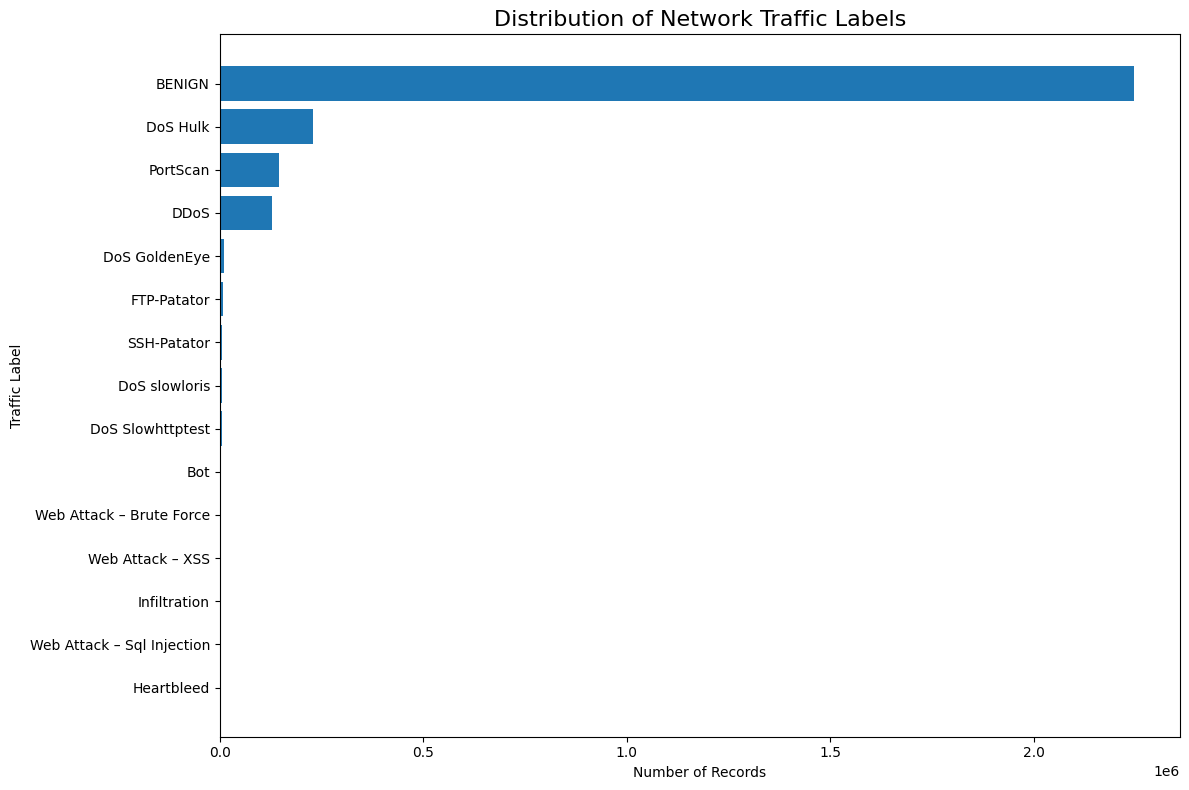

In [208]:
import pandas as pd
import matplotlib.pyplot as plt

# Verified label counts from the complete cleaned master dataset
label_counts = pd.Series({
    "BENIGN": 2247393,
    "DoS Hulk": 230123,
    "PortScan": 146111,
    "DDoS": 128025,
    "DoS GoldenEye": 10293,
    "FTP-Patator": 7935,
    "SSH-Patator": 5897,
    "DoS slowloris": 5796,
    "DoS Slowhttptest": 5499,
    "Bot": 1956,
    "Web Attack – Brute Force": 1507,
    "Web Attack – XSS": 652,
    "Infiltration": 36,
    "Web Attack – Sql Injection": 21,
    "Heartbleed": 11
})

# Sort labels from highest to lowest
label_counts = label_counts.sort_values(ascending=True)

# Create visualization
plt.figure(figsize=(12, 8))

plt.barh(
    label_counts.index,
    label_counts.values
)

plt.title(
    "Distribution of Network Traffic Labels",
    fontsize=16
)

plt.xlabel("Number of Records")
plt.ylabel("Traffic Label")

plt.tight_layout()
plt.show()

In [209]:
import pandas as pd

label_counts = pd.Series({
    "BENIGN": 2247393,
    "DoS Hulk": 230123,
    "PortScan": 146111,
    "DDoS": 128025,
    "DoS GoldenEye": 10293,
    "FTP-Patator": 7935,
    "SSH-Patator": 5897,
    "DoS slowloris": 5796,
    "DoS Slowhttptest": 5499,
    "Bot": 1956,
    "Web Attack – Brute Force": 1507,
    "Web Attack – XSS": 652,
    "Infiltration": 36,
    "Web Attack – Sql Injection": 21,
    "Heartbleed": 11
})

label_percentages = (label_counts / label_counts.sum()) * 100

distribution = pd.DataFrame({
    "Count": label_counts,
    "Percentage": label_percentages
})

distribution = distribution.sort_values(
    by="Count",
    ascending=False
)

print(distribution.round(4))

                              Count  Percentage
BENIGN                      2247393     80.5155
DoS Hulk                     230123      8.2444
PortScan                     146111      5.2346
DDoS                         128025      4.5866
DoS GoldenEye                 10293      0.3688
FTP-Patator                    7935      0.2843
SSH-Patator                    5897      0.2113
DoS slowloris                  5796      0.2076
DoS Slowhttptest               5499      0.1970
Bot                            1956      0.0701
Web Attack – Brute Force       1507      0.0540
Web Attack – XSS                652      0.0234
Infiltration                     36      0.0013
Web Attack – Sql Injection       21      0.0008
Heartbleed                       11      0.0004


In [210]:
print("Majority Class:")
print(distribution.iloc[0])

print("\nMinority Classes:")
print(distribution.tail(5))

Majority Class:
Count         2.247393e+06
Percentage    8.051550e+01
Name: BENIGN, dtype: float64

Minority Classes:
                            Count  Percentage
Web Attack – Brute Force     1507    0.053990
Web Attack – XSS              652    0.023359
Infiltration                   36    0.001290
Web Attack – Sql Injection     21    0.000752
Heartbleed                     11    0.000394


In [211]:
majority_count = distribution["Count"].max()
minority_count = distribution["Count"].min()

imbalance_ratio = majority_count / minority_count

print("Majority Class Count:", majority_count)
print("Minority Class Count:", minority_count)
print("Imbalance Ratio:", imbalance_ratio)

Majority Class Count: 2247393
Minority Class Count: 11
Imbalance Ratio: 204308.45454545456


In [212]:
import pandas as pd

file_path = "../data/processed/CyberThreat_Master_Cleaned.csv"

chunk_size = 100000

missing_counts = None

for chunk in pd.read_csv(file_path, chunksize=chunk_size, low_memory=False):

    chunk_missing = chunk.isnull().sum()

    if missing_counts is None:
        missing_counts = chunk_missing
    else:
        missing_counts += chunk_missing

print("Missing Values in Each Column:")
print(missing_counts[missing_counts > 0])

print("\nTotal Missing Values:")
print(missing_counts.sum())

Missing Values in Each Column:
Series([], dtype: int64)

Total Missing Values:
0


In [213]:
import pandas as pd

file_path = "../data/processed/CyberThreat_Master_Cleaned.csv"

chunk_size = 100000

total_rows = 0
duplicate_count = 0

for chunk in pd.read_csv(file_path, chunksize=chunk_size, low_memory=False):

    total_rows += len(chunk)

    duplicate_count += chunk.duplicated().sum()

print("Total Rows:", total_rows)
print("Duplicate Rows Found:", duplicate_count)

Total Rows: 2791255
Duplicate Rows Found: 0


In [214]:
import pandas as pd

file_path = "../data/processed/CyberThreat_Master_Cleaned.csv"

df_sample = pd.read_csv(file_path, nrows=1000, low_memory=False)

print("Column Data Types:")
print(df_sample.dtypes)

Column Data Types:
Flow ID              object
Source IP            object
Source Port           int64
Destination IP       object
Destination Port      int64
                     ...   
Idle Std            float64
Idle Max              int64
Idle Min              int64
Label                object
Day                  object
Length: 78, dtype: object


In [215]:
print("Data Type Counts:")
print(df_sample.dtypes.value_counts())

print("\nNumerical Columns:")
print(df_sample.select_dtypes(include=["int64", "float64"]).columns.tolist())

print("\nObject Columns:")
print(df_sample.select_dtypes(include=["object"]).columns.tolist())

Data Type Counts:
int64      48
float64    24
object      6
Name: count, dtype: int64

Numerical Columns:
['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST F

In [216]:
raw_file = Path("../data/raw/TrafficLabelling/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv")
cleaned_file = output_dir / "Friday_PortScan_cleaned.csv"

# Count original raw rows
raw_count = 0

for chunk in pd.read_csv(
    raw_file,
    chunksize=CHUNK_SIZE,
    low_memory=False
):
    chunk.columns = chunk.columns.str.strip()
    raw_count += len(chunk)

# Count cleaned rows
cleaned_count = 0

for chunk in pd.read_csv(
    cleaned_file,
    usecols=["Label"],
    chunksize=CHUNK_SIZE
):
    cleaned_count += len(chunk)

print("FRIDAY PORTSCAN VERIFICATION")
print("-" * 40)
print("Original raw rows:", raw_count)
print("Actual cleaned rows:", cleaned_count)
print("Difference:", raw_count - cleaned_count)
print("Expected cleaned rows: 286095")
print("Missing against expected:", 286095 - cleaned_count)

FRIDAY PORTSCAN VERIFICATION
----------------------------------------
Original raw rows: 286467
Actual cleaned rows: 286095
Difference: 372
Expected cleaned rows: 286095
Missing against expected: 0


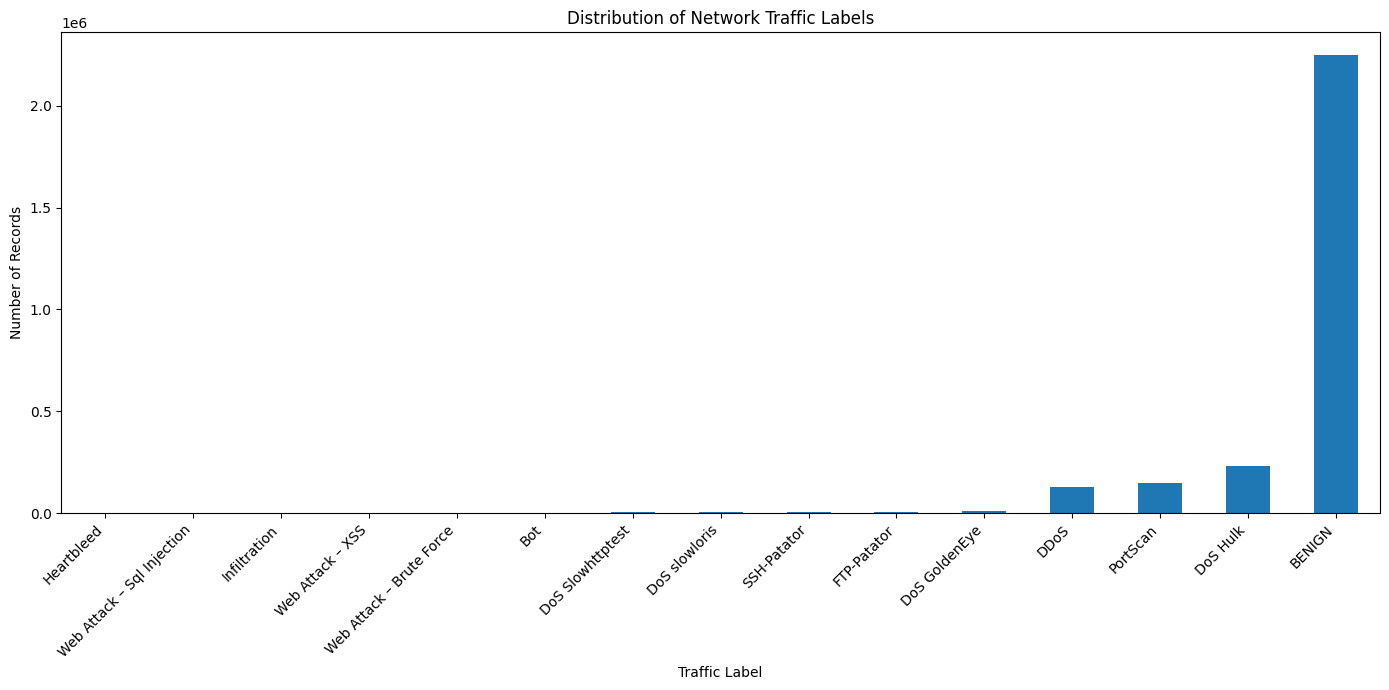

In [217]:
# Duplicate label-distribution visualization; use the verified label_counts
# created in the preceding analysis cell rather than an undefined df.
import matplotlib.pyplot as plt

if "label_counts" not in globals():
    master_file = Path("../data/processed/CyberThreat_Master_Cleaned.csv")
    label_counts = pd.Series(dtype="int64")
    for chunk in pd.read_csv(master_file, usecols=["Label"], chunksize=100000):
        label_counts = label_counts.add(chunk["Label"].value_counts(), fill_value=0)

plt.figure(figsize=(14, 7))
label_counts.sort_values().plot(kind="bar")
plt.title("Distribution of Network Traffic Labels")
plt.xlabel("Traffic Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [218]:
raw_file = Path("../data/raw/TrafficLabelling/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv")
cleaned_file = output_dir / "Friday_PortScan_cleaned.csv"

raw_labels = {}
cleaned_labels = {}

# Count labels in original raw file
for chunk in pd.read_csv(raw_file, chunksize=CHUNK_SIZE, low_memory=False):
    chunk.columns = chunk.columns.str.strip()

    counts = chunk["Label"].astype(str).str.strip().value_counts()

    for label, count in counts.items():
        raw_labels[label] = raw_labels.get(label, 0) + count

# Count labels in cleaned file
for chunk in pd.read_csv(cleaned_file, usecols=["Label"], chunksize=CHUNK_SIZE):
    counts = chunk["Label"].astype(str).str.strip().value_counts()

    for label, count in counts.items():
        cleaned_labels[label] = cleaned_labels.get(label, 0) + count

# Compare both datasets
label_comparison = pd.DataFrame({
    "Raw_Count": pd.Series(raw_labels),
    "Cleaned_Count": pd.Series(cleaned_labels)
}).fillna(0).astype(int)

label_comparison["Difference"] = (
    label_comparison["Raw_Count"] -
    label_comparison["Cleaned_Count"]
)

print("FRIDAY PORTSCAN LABEL COMPARISON")
display(label_comparison.sort_values("Difference", ascending=False))

FRIDAY PORTSCAN LABEL COMPARISON


,Raw_Count,Cleaned_Count,Difference
BENIGN,127537,127291,246
PortScan,158930,158804,126


In [219]:
from pathlib import Path
import pandas as pd
import numpy as np

# 1. File paths
raw_file = Path("../data/raw/TrafficLabelling/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv")
output_file = output_dir / "Friday_PortScan_cleaned.csv"

# 2. Constant columns to remove
constant_columns = [
    "Bwd PSH Flags",
    "Bwd URG Flags",
    "Fwd Avg Bytes/Bulk",
    "Fwd Avg Packets/Bulk",
    "Fwd Avg Bulk Rate",
    "Bwd Avg Bytes/Bulk",
    "Bwd Avg Packets/Bulk",
    "Bwd Avg Bulk Rate"
]

# 3. Counters
total_raw = 0
invalid_rows = 0
duplicate_rows = 0
final_rows = 0

seen_hashes = set()
first_chunk = True

# 4. Remove only the incorrect Friday PortScan output
if output_file.exists():
    output_file.unlink()

# 5. Process original CSV in chunks
for chunk in pd.read_csv(
    raw_file,
    chunksize=CHUNK_SIZE,
    low_memory=False
):

    chunk.columns = chunk.columns.str.strip()
    total_raw += len(chunk)

    # Replace infinite values with NaN
    chunk = chunk.replace([np.inf, -np.inf], np.nan)

    # Remove rows with missing flow-rate values
    invalid_mask = chunk[
        ["Flow Bytes/s", "Flow Packets/s"]
    ].isna().any(axis=1)

    invalid_rows += invalid_mask.sum()

    chunk = chunk.loc[~invalid_mask].copy()

    # Remove constant columns
    chunk.drop(
        columns=constant_columns,
        errors="ignore",
        inplace=True
    )

    # Add Day column
    chunk["Day"] = "Friday"

    # Remove duplicates across all chunks
    row_hashes = pd.util.hash_pandas_object(
        chunk,
        index=False
    )

    keep_mask = []

    for h in row_hashes:
        if h in seen_hashes:
            keep_mask.append(False)
            duplicate_rows += 1
        else:
            keep_mask.append(True)
            seen_hashes.add(h)

    chunk = chunk.loc[keep_mask].copy()

    # Save cleaned data
    if not chunk.empty:
        chunk.to_csv(
            output_file,
            mode="w" if first_chunk else "a",
            header=first_chunk,
            index=False
        )

        first_chunk = False
        final_rows += len(chunk)

    print("Processed rows:", total_raw)

# 6. Final report
print("\nFRIDAY PORTSCAN CLEANING REPORT")
print("-" * 40)
print("Original rows:", total_raw)
print("Invalid rows removed:", invalid_rows)
print("Duplicate rows removed:", duplicate_rows)
print("Final cleaned rows:", final_rows)
print("Columns:", len(chunk.columns))
print("Output file:", output_file)
print("File exists:", output_file.exists())

Processed rows: 100000
Processed rows: 200000
Processed rows: 286467

FRIDAY PORTSCAN CLEANING REPORT
----------------------------------------
Original rows: 286467
Invalid rows removed: 371
Duplicate rows removed: 1
Final cleaned rows: 286095
Columns: 78
Output file: ..\data\processed\Friday_PortScan_cleaned.csv
File exists: True


In [220]:
# FINAL CLEANED DATASET VERIFICATION
from pathlib import Path
import pandas as pd

output_dir = Path("../data/processed")
CHUNK_SIZE = 100000
expected_rows = {
    "Friday_DDoS_cleaned.csv": 225709,
    "Friday_PortScan_cleaned.csv": 286095,
    "Friday_Morning_cleaned.csv": 190909,
    "Monday_cleaned.csv": 529450,
    "Thursday_Infiltration_cleaned.csv": 288253,
    "Thursday_WebAttacks_cleaned.csv": 170230,
    "Tuesday_cleaned.csv": 445641,
    "Wednesday_cleaned.csv": 691390,
}

total_rows = 0
all_verified = True
print("FINAL CLEANED DATASET VERIFICATION")
print("=" * 65)

for filename, expected in expected_rows.items():
    filepath = output_dir / filename
    if not filepath.exists():
        actual = None
        status = "MISSING"
        all_verified = False
    else:
        actual = 0
        for chunk in pd.read_csv(filepath, usecols=["Label"], chunksize=CHUNK_SIZE):
            actual += len(chunk)
        status = "PASS" if actual == expected else "CHECK"
        if actual != expected:
            all_verified = False
        total_rows += actual
    print(f"{filename}: {actual if actual is not None else 'MISSING'} | Expected: {expected:,} | {status}")

print("=" * 65)
print("Total cleaned rows:", f"{total_rows:,}")
print("All files verified:", all_verified)


FINAL CLEANED DATASET VERIFICATION
Friday_DDoS_cleaned.csv: 225709 | Expected: 225,709 | PASS
Friday_PortScan_cleaned.csv: 286095 | Expected: 286,095 | PASS
Friday_Morning_cleaned.csv: 190909 | Expected: 190,909 | PASS
Monday_cleaned.csv: 529450 | Expected: 529,450 | PASS
Thursday_Infiltration_cleaned.csv: 288253 | Expected: 288,253 | PASS
Thursday_WebAttacks_cleaned.csv: 170230 | Expected: 170,230 | PASS
Tuesday_cleaned.csv: 445641 | Expected: 445,641 | PASS
Wednesday_cleaned.csv: 691390 | Expected: 691,390 | PASS
Total cleaned rows: 2,827,677
All files verified: True


In [221]:
# DAY-WISE ATTACK DISTRIBUTION
from collections import Counter
import pandas as pd
from pathlib import Path

output_dir = Path("../data/processed")
CHUNK_SIZE = 100000
cleaned_files = [
    output_dir / "Friday_DDoS_cleaned.csv",
    output_dir / "Friday_PortScan_cleaned.csv",
    output_dir / "Friday_Morning_cleaned.csv",
    output_dir / "Monday_cleaned.csv",
    output_dir / "Thursday_Infiltration_cleaned.csv",
    output_dir / "Thursday_WebAttacks_cleaned.csv",
    output_dir / "Tuesday_cleaned.csv",
    output_dir / "Wednesday_cleaned.csv",
]

day_label_counts = Counter()
for path in cleaned_files:
    if not path.exists():
        print("MISSING:", path)
        continue
    print("Analysing:", path.name)
    for chunk in pd.read_csv(path, usecols=["Day", "Label"], chunksize=CHUNK_SIZE, low_memory=False):
        day_label_counts.update(chunk.groupby(["Day", "Label"]).size().to_dict())

day_label_df = pd.DataFrame([
    {"Day": key[0], "Label": key[1], "Count": value}
    for key, value in day_label_counts.items()
])
day_label_df = day_label_df.sort_values(["Day", "Count"], ascending=[True, False]).reset_index(drop=True)
print("\nDAY-WISE ATTACK DISTRIBUTION")
display(day_label_df)
print("\nTotal records analysed:", day_label_df["Count"].sum())
print("Unique attack labels:", day_label_df["Label"].nunique())


Analysing: Friday_DDoS_cleaned.csv
Analysing: Friday_PortScan_cleaned.csv
Analysing: Friday_Morning_cleaned.csv
Analysing: Monday_cleaned.csv
Analysing: Thursday_Infiltration_cleaned.csv
Analysing: Thursday_WebAttacks_cleaned.csv
Analysing: Tuesday_cleaned.csv
Analysing: Wednesday_cleaned.csv

DAY-WISE ATTACK DISTRIBUTION


,Day,Label,Count
0,Friday,BENIGN,413928
1,Friday,PortScan,158804
2,Friday,DDoS,128025
3,Friday,Bot,1956
4,Monday,BENIGN,529450
5,Thursday,BENIGN,456267
6,Thursday,Web Attack – Brute Force,1507
7,Thursday,Web Attack – XSS,652
8,Thursday,Infiltration,36
9,Thursday,Web Attack – Sql Injection,21



Total records analysed: 2827677
Unique attack labels: 15


In [222]:
import pandas as pd
import numpy as np
from pathlib import Path

# Re-establish paths so this cell can run after a kernel restart.
output_dir = Path("../data/processed")
cleaned_files = [
    output_dir / "Friday_DDoS_cleaned.csv",
    output_dir / "Friday_PortScan_cleaned.csv",
    output_dir / "Friday_Morning_cleaned.csv",
    output_dir / "Monday_cleaned.csv",
    output_dir / "Thursday_Infiltration_cleaned.csv",
    output_dir / "Thursday_WebAttacks_cleaned.csv",
    output_dir / "Tuesday_cleaned.csv",
    output_dir / "Wednesday_cleaned.csv",
]
CHUNK_SIZE = 100000

# 1. Sampling limits
sample_limits = {
    "BENIGN": 4000,
    "PortScan": 4000,
    "DDoS": 4000,
    "DoS Hulk": 4000,
    "DoS GoldenEye": 1500,
    "FTP-Patator": 1500,
    "SSH-Patator": 1500,
    "DoS slowloris": 1500,
    "DoS Slowhttptest": 1500,
    "Bot": 1000,
    "Web Attack – Brute Force": 1000,
    "Web Attack – XSS": 652,
    "Infiltration": 36,
    "Web Attack – Sql Injection": 21,
    "Heartbleed": 11
}

# 2. Output directory
sample_dir = Path("../data/sample")
sample_dir.mkdir(parents=True, exist_ok=True)

master_sample_file = sample_dir / "CyberThreat_Master_Dataset.csv"

# 3. Reproducible random generator
rng = np.random.default_rng(42)

# 4. Store selected records
reservoir = {}

# 5. Process all cleaned files in chunks
for path in cleaned_files:

    print("Sampling:", path.name)

    for chunk in pd.read_csv(
        path,
        chunksize=CHUNK_SIZE,
        low_memory=False
    ):

        chunk.columns = chunk.columns.str.strip()

        # Generate random priority for every row
        chunk["_sample_key"] = rng.random(len(chunk))

        # Group by Day and Label
        for (day, label), group in chunk.groupby(
            ["Day", "Label"],
            sort=False
        ):

            if label not in sample_limits:
                continue

            limit = sample_limits[label]
            key = (day, label)

            # Combine previous candidates with current chunk
            if key in reservoir:
                candidates = pd.concat(
                    [reservoir[key], group],
                    ignore_index=True
                )
            else:
                candidates = group.copy()

            # Keep the lowest random priorities
            reservoir[key] = candidates.nsmallest(
                limit,
                "_sample_key"
            )

    print("Completed:", path.name)

# 6. Combine selected records
master_df = pd.concat(
    reservoir.values(),
    ignore_index=True
)

# Remove temporary sampling column
master_df.drop(
    columns=["_sample_key"],
    inplace=True
)

# Shuffle final dataset
master_df = master_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# 7. Save master dataset
master_df.to_csv(
    master_sample_file,
    index=False
)

print("\nMASTER DATASET CREATED")
print("=" * 45)
print("Total rows:", len(master_df))
print("Total columns:", len(master_df.columns))
print("Unique labels:", master_df["Label"].nunique())
print("Unique days:", master_df["Day"].nunique())
print("File:", master_sample_file)
print("File exists:", master_sample_file.exists())

Sampling: Friday_DDoS_cleaned.csv
Completed: Friday_DDoS_cleaned.csv
Sampling: Friday_PortScan_cleaned.csv
Completed: Friday_PortScan_cleaned.csv
Sampling: Friday_Morning_cleaned.csv
Completed: Friday_Morning_cleaned.csv
Sampling: Monday_cleaned.csv
Completed: Monday_cleaned.csv
Sampling: Thursday_Infiltration_cleaned.csv
Completed: Thursday_Infiltration_cleaned.csv
Sampling: Thursday_WebAttacks_cleaned.csv
Completed: Thursday_WebAttacks_cleaned.csv
Sampling: Tuesday_cleaned.csv
Completed: Tuesday_cleaned.csv
Sampling: Wednesday_cleaned.csv
Completed: Wednesday_cleaned.csv

MASTER DATASET CREATED
Total rows: 42220
Total columns: 78
Unique labels: 15
Unique days: 5
File: ..\data\sample\CyberThreat_Master_Dataset.csv
File exists: True


In [223]:
# Load and verify the saved sampled master dataset
from pathlib import Path
import pandas as pd

sample_dir = Path("../data/sample")
master_sample_file = sample_dir / "CyberThreat_Master_Dataset.csv"

if not master_sample_file.exists():
    raise FileNotFoundError(f"Sampled master dataset not found: {master_sample_file}. Run the sampling cell first.")

master_check = pd.read_csv(master_sample_file, low_memory=False)
print("CYBERTHREAT AI MASTER DATASET")
print("=" * 50)
print("Total rows:", len(master_check))
print("Total columns:", len(master_check.columns))
print("Unique labels:", master_check["Label"].nunique())
print("Unique days:", master_check["Day"].nunique())

checks = {
    "Below 50,000 rows": len(master_check) < 50000,
    "Expected 78 columns before duplicate-column removal": len(master_check.columns) == 78,
    "All 15 labels preserved": master_check["Label"].nunique() == 15,
    "All 5 days represented": master_check["Day"].nunique() == 5,
    "No missing labels": master_check["Label"].notna().all(),
    "No missing days": master_check["Day"].notna().all(),
    "No temporary sampling column": "_sample_key" not in master_check.columns,
}
print("\nVERIFICATION CHECKLIST")
for check, result in checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")
print("\nATTACK LABEL DISTRIBUTION")
display(master_check["Label"].value_counts().to_frame("Count"))
print("\nDAY DISTRIBUTION")
display(master_check["Day"].value_counts().to_frame("Count"))


CYBERTHREAT AI MASTER DATASET
Total rows: 42220
Total columns: 78
Unique labels: 15
Unique days: 5

VERIFICATION CHECKLIST
Below 50,000 rows: PASS
Expected 78 columns before duplicate-column removal: PASS
All 15 labels preserved: PASS
All 5 days represented: PASS
No missing labels: PASS
No missing days: PASS
No temporary sampling column: PASS

ATTACK LABEL DISTRIBUTION


,Count
Label,
BENIGN,20000
DDoS,4000
DoS Hulk,4000
PortScan,4000
FTP-Patator,1500
DoS Slowhttptest,1500
DoS GoldenEye,1500
SSH-Patator,1500
DoS slowloris,1500



DAY DISTRIBUTION


,Count
Day,
Friday,13000
Wednesday,12511
Tuesday,7000
Thursday,5709
Monday,4000


In [224]:
import pandas as pd
from pathlib import Path

# 1. Load the existing sample. Do NOT resample.
master_df = pd.read_csv(master_sample_file, low_memory=False)

# 2. Standardize label text
master_df["Label"] = (
    master_df["Label"]
    .astype(str)
    .str.replace("–", "-", regex=False)
    .str.strip()
)

# 3. Print actual columns
print("MASTER DATASET COLUMNS")
print("=" * 60)

print(master_df.columns.tolist())
print("\nTotal columns:", len(master_df.columns))

# 4. Check important analytics columns
required_columns = [
    "Source IP",
    "Destination IP",
    "Timestamp",
    "Destination Port",
    "Day",
    "Label"
]

print("\nIMPORTANT COLUMN CHECK")
for column in required_columns:
    print(
        f"{column}:",
        "PRESENT" if column in master_df.columns else "MISSING"
    )

# 5. Check constant columns
constant_columns = [
    "Bwd PSH Flags",
    "Bwd URG Flags",
    "Fwd Avg Bytes/Bulk",
    "Fwd Avg Packets/Bulk",
    "Fwd Avg Bulk Rate",
    "Bwd Avg Bytes/Bulk",
    "Bwd Avg Packets/Bulk",
    "Bwd Avg Bulk Rate"
]

print("\nCONSTANT COLUMN CHECK")
for column in constant_columns:
    print(
        f"{column}:",
        "REMOVED" if column not in master_df.columns else "STILL PRESENT"
    )

# 6. Data quality checks
print("\nDATA QUALITY CHECKS")
print("=" * 60)

print("Total rows:", len(master_df))
print("Total columns:", len(master_df.columns))
print("Missing values:", master_df.isna().sum().sum())
print("Duplicate rows:", master_df.duplicated().sum())
print("Unique labels:", master_df["Label"].nunique())
print("Unique days:", master_df["Day"].nunique())

# 7. Day-wise label distribution
print("\nDAY-WISE LABEL DISTRIBUTION")
display(
    master_df.groupby(["Day", "Label"])
    .size()
    .unstack(fill_value=0)
)

# 8. Overall label distribution
print("\nLABEL DISTRIBUTION")
display(master_df["Label"].value_counts().to_frame("Count"))

# 9. Label proportions
print("\nTOP 3 LABEL PROPORTIONS")
display(
    master_df["Label"]
    .value_counts(normalize=True)
    .head(3)
    .mul(100)
    .round(2)
    .to_frame("Percentage")
)

# 10. Save final master dataset
final_master_path = Path("../data/master_dataset.csv")

master_df.to_csv(final_master_path, index=False)

print("\nMASTER DATASET LOCKED")
print("=" * 60)
print("Saved at:", final_master_path)
print("File exists:", final_master_path.exists())
print("Final rows:", len(master_df))
print("Final columns:", len(master_df.columns))

MASTER DATASET COLUMNS
['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count'

Label,BENIGN,Bot,DDoS,DoS GoldenEye,DoS Hulk,DoS Slowhttptest,DoS slowloris,FTP-Patator,Heartbleed,Infiltration,PortScan,SSH-Patator,Web Attack - Brute Force,Web Attack - Sql Injection,Web Attack - XSS
Day,,,,,,,,,,,,,,,
Friday,4000,1000,4000,0,0,0,0,0,0,0,4000,0,0,0,0
Monday,4000,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Thursday,4000,0,0,0,0,0,0,0,0,36,0,0,1000,21,652
Tuesday,4000,0,0,0,0,0,0,1500,0,0,0,1500,0,0,0
Wednesday,4000,0,0,1500,4000,1500,1500,0,11,0,0,0,0,0,0



LABEL DISTRIBUTION


,Count
Label,
BENIGN,20000
DDoS,4000
DoS Hulk,4000
PortScan,4000
FTP-Patator,1500
DoS Slowhttptest,1500
DoS GoldenEye,1500
SSH-Patator,1500
DoS slowloris,1500



TOP 3 LABEL PROPORTIONS


,Percentage
Label,
BENIGN,47.37
DDoS,9.47
DoS Hulk,9.47



MASTER DATASET LOCKED
Saved at: ..\data\master_dataset.csv
File exists: True
Final rows: 42220
Final columns: 78


In [225]:
# MASTER DATASET QUALITY CHECKS
from pathlib import Path
import pandas as pd

final_master_path = Path("../data/master_dataset.csv")
if "master_df" not in globals():
    if not final_master_path.exists():
        raise FileNotFoundError(f"Master dataset not found: {final_master_path}. Run the sampling and save cells first.")
    master_df = pd.read_csv(final_master_path, low_memory=False)

print("Total missing values:", master_df.isna().sum().sum())
print("Duplicate rows:", master_df.duplicated().sum())

if "Fwd Header Length.1" in master_df.columns and "Fwd Header Length" in master_df.columns:
    print("Fwd Header Length columns identical:", master_df["Fwd Header Length"].equals(master_df["Fwd Header Length.1"]))
else:
    print("Duplicate Fwd Header Length column is not present (already removed or unavailable).")

print("\nTimestamp data type:")
print(master_df["Timestamp"].dtype if "Timestamp" in master_df.columns else "Timestamp column missing")

if final_master_path.exists():
    print("\nMaster dataset size:", round(final_master_path.stat().st_size / (1024 * 1024), 2), "MB")
else:
    print("Master dataset file has not yet been saved.")


Total missing values: 0
Duplicate rows: 0
Fwd Header Length columns identical: True

Timestamp data type:
object

Master dataset size: 21.13 MB


In [226]:
# FINAL MASTER DATASET CLEANUP (idempotent)
from pathlib import Path
import pandas as pd

final_master_path = Path("../data/master_dataset.csv")
if "master_df" not in globals():
    if not final_master_path.exists():
        raise FileNotFoundError(f"Master dataset not found: {final_master_path}")
    master_df = pd.read_csv(final_master_path, low_memory=False)

# Remove the duplicate column only if it exists.
master_df.drop(columns=["Fwd Header Length.1"], inplace=True, errors="ignore")

# Parse timestamps safely; invalid values become NaT and are counted.
if "Timestamp" in master_df.columns:
    master_df["Timestamp"] = pd.to_datetime(
        master_df["Timestamp"], format="mixed", dayfirst=True, errors="coerce"
    )

print("TIMESTAMP VERIFICATION")
print("-" * 40)
if "Timestamp" in master_df.columns:
    print("Timestamp data type:", master_df["Timestamp"].dtype)
    print("Invalid timestamps:", master_df["Timestamp"].isna().sum())

print("\nFINAL DATASET VERIFICATION")
print("-" * 40)
print("Rows:", len(master_df))
print("Columns:", len(master_df.columns))
print("Missing values:", master_df.isna().sum().sum())
print("Duplicate rows:", master_df.duplicated().sum())

master_df.to_csv(final_master_path, index=False)
print("\nFINAL MASTER DATASET SAVED")
print("Location:", final_master_path)
print("File size:", round(final_master_path.stat().st_size / (1024 * 1024), 2), "MB")


TIMESTAMP VERIFICATION
----------------------------------------
Timestamp data type: datetime64[ns]
Invalid timestamps: 0

FINAL DATASET VERIFICATION
----------------------------------------
Rows: 42220
Columns: 77
Missing values: 0
Duplicate rows: 0

FINAL MASTER DATASET SAVED
Location: ..\data\master_dataset.csv
File size: 21.11 MB


In [227]:
# RESTORE MASTER DATASET FROM SAVED FILE
from pathlib import Path
import pandas as pd
import numpy as np

output_dir = Path("../data/processed")
sample_dir = Path("../data/sample")
final_master_path = Path("../data/master_dataset.csv")

if not final_master_path.exists():
    raise FileNotFoundError(f"Final master dataset not found: {final_master_path}")

master_df = pd.read_csv(final_master_path, low_memory=False)
print("MASTER DATASET RESTORED")
print("-" * 40)
print("Rows:", len(master_df))
print("Columns:", len(master_df.columns))
print("File exists:", final_master_path.exists())
print("Labels:", master_df["Label"].nunique())
print("Days:", master_df["Day"].nunique())


MASTER DATASET RESTORED
----------------------------------------
Rows: 42220
Columns: 77
File exists: True
Labels: 15
Days: 5


In [228]:
# FINAL DATASET VERIFICATION (safe to rerun)
from pathlib import Path
import pandas as pd

final_master_path = Path("../data/master_dataset.csv")
if "master_df" not in globals():
    master_df = pd.read_csv(final_master_path, low_memory=False)

master_df.drop(columns=["Fwd Header Length.1"], inplace=True, errors="ignore")
if "Timestamp" in master_df.columns:
    master_df["Timestamp"] = pd.to_datetime(
        master_df["Timestamp"], format="mixed", dayfirst=True, errors="coerce"
    )

print("FINAL DATASET VERIFICATION")
print("-" * 45)
print("Rows:", len(master_df))
print("Columns:", len(master_df.columns))
print("Missing values:", master_df.isna().sum().sum())
print("Duplicate rows:", master_df.duplicated().sum())
print("Invalid timestamps:", master_df["Timestamp"].isna().sum() if "Timestamp" in master_df.columns else "N/A")
print("Timestamp type:", master_df["Timestamp"].dtype if "Timestamp" in master_df.columns else "N/A")

master_df.to_csv(final_master_path, index=False)
print("\nOptimized master dataset saved successfully!")


FINAL DATASET VERIFICATION
---------------------------------------------
Rows: 42220
Columns: 77
Missing values: 0
Duplicate rows: 0
Invalid timestamps: 0
Timestamp type: datetime64[ns]

Optimized master dataset saved successfully!


In [229]:
# Confirm timestamp dtype without relying on an undefined variable
if "master_df" not in globals():
    master_df = pd.read_csv("../data/master_dataset.csv", low_memory=False)
master_df["Timestamp"].dtype


dtype('<M8[ns]')